In [1]:
%matplotlib inline
import json
import time
import shutil
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True

## 1. Датасет

Amazon Reviews 2023 (McAuley Lab, UCSD), категория Video_Games.

Поля взаимодействий: `user_id`, `parent_asin` (товар), `rating` (1–5),
`timestamp` (unix ms). Метаданные товара: `title`, `main_category`,
`categories`, `description`, `price`, `store`.

Рекомендуем товары, с которыми пользователь взаимодействует в следующем временном
окне. Релевантными считаем товары с любой оценкой от 1 до 5, входящие в множество
кандидатов `C` (раздел 4). Здесь положительный сигнал означает наличие отзыва,
а не высокую оценку товара.

Метаданные используются в FM, оценки и время отзывов — в timeSVD++.


In [2]:
RAW_REV = Path('data/raw/Video_Games.jsonl')
RAW_META = Path('data/raw/meta_Video_Games.jsonl')
BASE_URL = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e/raw'

for dest, remote in [(RAW_REV, 'review_categories/Video_Games.jsonl'),
                     (RAW_META, 'meta_categories/meta_Video_Games.jsonl')]:
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        temp = dest.with_suffix('.part')
        print(f'Загрузка {dest.name}')
        with urllib.request.urlopen(f'{BASE_URL}/{remote}', timeout=120) as response, temp.open('wb') as output:
            shutil.copyfileobj(response, output)
        temp.replace(dest)

raw_stats = pl.scan_ndjson(RAW_REV).select(
    pl.len().alias('отзывов'),
    pl.col('user_id').n_unique().alias('пользователей'),
    pl.col('parent_asin').n_unique().alias('товаров'),
).collect(engine='streaming')
display(raw_stats)

отзывов,пользователей,товаров
u32,u32,u32
4624615,2766656,137249


## 2. Очистка и подготовка

Подготовка данных с seed=42.

1. Объединяем отзывы на одну пару (user, item): берём средний рейтинг и минимальный
   timestamp — время первого отзыва.
2. Итеративно удаляем пользователей и товары с менее чем 5 взаимодействиями
   не более пяти проходов. Это приближение к 5-core: после последнего прохода
   у некоторых пользователей может остаться меньше пяти взаимодействий.
3. Если осталось больше 1,9 млн взаимодействий, случайно отбираем целые профили
   пользователей с seed=42. В этом прогоне подвыборка не потребовалась.
4. Применяем фильтр 3-core после отбора.
5. Строим целочисленные индексы пользователей и товаров, таблицу метаданных
   и временное разбиение.

Число записей на каждом этапе приведено в `summary.json` ниже.

In [3]:
import json
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import polars as pl
from scipy import sparse

def load_raw_reviews(path: str | Path) -> pl.DataFrame:
    df = pl.scan_ndjson(str(path)).select(pl.col('rating').cast(pl.Float32), pl.col('user_id').alias('user_id_raw'), pl.col('parent_asin').alias('item_id_raw'), pl.col('timestamp').cast(pl.Int64).alias('ts_ms')).collect(engine='streaming')
    df = df.drop_nulls().filter((pl.col('rating') >= 1.0) & (pl.col('rating') <= 5.0)).with_columns((pl.col('ts_ms') / 1000.0).cast(pl.Float64).alias('ts')).drop('ts_ms')
    df = df.group_by(['user_id_raw', 'item_id_raw']).agg(pl.col('rating').mean().cast(pl.Float32).alias('rating'), pl.col('ts').min().alias('ts'), pl.len().alias('n_reviews'))
    return df

def load_raw_meta(path: str | Path) -> pl.DataFrame:
    rows = []
    seen: set[str] = set()
    with open(path, 'rb') as f:
        for line in f:
            d = json.loads(line)
            pa = d.get('parent_asin') or d.get('asin')
            if pa is None or pa in seen:
                continue
            seen.add(pa)
            title = d.get('title')
            cat = d.get('categories')
            desc = d.get('description')
            rows.append({'item_id_raw': str(pa), 'cat_main': str(d.get('main_category') or 'other'), 'cat_path': '|'.join((str(x) for x in cat[:2])) if isinstance(cat, list) and cat else 'other', 'title': (str(title)[:120] if title is not None else '') or '', 'store': str(d.get('store') or ''), 'price': _parse_price(d.get('price')), 'desc_len': int(sum((len(str(x)) for x in desc))) if isinstance(desc, list) and desc else 0})
    df = pl.DataFrame({'item_id_raw': pl.Series([r['item_id_raw'] for r in rows], dtype=pl.Utf8), 'cat_main': pl.Series([r['cat_main'] for r in rows], dtype=pl.Utf8), 'cat_path': pl.Series([r['cat_path'] for r in rows], dtype=pl.Utf8), 'title': pl.Series([r['title'] for r in rows], dtype=pl.Utf8), 'store': pl.Series([r['store'] for r in rows], dtype=pl.Utf8), 'price': pl.Series([r['price'] for r in rows], dtype=pl.Float32), 'desc_len': pl.Series([r['desc_len'] for r in rows], dtype=pl.Int32)})
    df = df.with_columns(title_len=pl.col('title').str.len_chars().cast(pl.Int32))
    return df

def _parse_price(v) -> float:
    import re
    if v is None:
        return float('nan')
    if isinstance(v, (int, float)):
        return float(v)
    m = re.search('\\d+(?:\\.\\d+)?', str(v))
    return float(m.group()) if m else float('nan')

def filter_core(df: pl.DataFrame, min_n: int, max_rounds: int=5) -> pl.DataFrame:
    prev = -1
    for _ in range(max_rounds):
        cu = df.group_by('user_id_raw').agg(pl.len().alias('cnt'))
        df = df.join(cu.filter(pl.col('cnt') >= min_n).select('user_id_raw'), on='user_id_raw', how='semi')
        ci = df.group_by('item_id_raw').agg(pl.len().alias('cnt'))
        df = df.join(ci.filter(pl.col('cnt') >= min_n).select('item_id_raw'), on='item_id_raw', how='semi')
        if df.height == prev:
            break
        prev = df.height
    return df

def sample_users_to_cap(df: pl.DataFrame, cap: int, seed: int) -> tuple[pl.DataFrame, dict]:
    if df.height <= cap:
        return (df, {'sampling': 'not-needed', 'cap': cap})
    users = np.sort(df['user_id_raw'].unique().to_numpy().astype('U'))
    cnt = df.group_by('user_id_raw').len().sort('user_id_raw').drop('user_id_raw')['len'].to_numpy()
    assert len(cnt) == len(users)
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(users))
    cum = np.cumsum(cnt[perm])
    n_keep = int(np.searchsorted(cum, cap, side='right'))
    if n_keep < 1:
        n_keep = 1
    keep = np.sort(users[perm[:n_keep]])
    keep_df = pl.DataFrame({'user_id_raw': pl.Series(keep, dtype=pl.Utf8)})
    df = df.join(keep_df, on='user_id_raw', how='semi')
    return (df, {'sampling': 'uniform-random-users', 'cap': cap, 'users_kept': int(n_keep), 'users_total_before': int(len(users))})

def prepare_dataset(raw_reviews: str | Path, raw_meta: str | Path, out_dir: str | Path, *, seed: int=42, core_min: int=5, final_core_min: int=3, interactions_cap: int=2000000, sample_target: int=1900000) -> dict:
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    reviews = load_raw_reviews(raw_reviews)
    n_raw = reviews.height
    reviews = filter_core(reviews, core_min)
    n_core = reviews.height
    reviews, sample_info = sample_users_to_cap(reviews, sample_target, seed=seed)
    n_sampled = reviews.height
    reviews = filter_core(reviews, final_core_min)
    n_final = reviews.height
    users_sorted = np.sort(reviews['user_id_raw'].unique().to_numpy().astype('U'))
    items_sorted = np.sort(reviews['item_id_raw'].unique().to_numpy().astype('U'))
    u_idx = np.searchsorted(users_sorted, reviews['user_id_raw'].to_numpy().astype('U'))
    i_idx = np.searchsorted(items_sorted, reviews['item_id_raw'].to_numpy().astype('U'))
    df = pl.DataFrame({'user_idx': u_idx.astype(np.int32), 'item_idx': i_idx.astype(np.int32), 'rating': reviews['rating'], 'ts': reviews['ts']}).sort(['ts', 'user_idx', 'item_idx'])
    n_users, n_items = (len(users_sorted), len(items_sorted))
    summary = {'category': Path(raw_reviews).stem.replace('.jsonl', ''), 'raw_interactions': int(n_raw), 'after_5core': int(n_core), 'after_sampling': int(n_sampled), 'sampling': sample_info, 'final_interactions': int(n_final), 'final_users': int(n_users), 'final_items': int(n_items), 'ts_min': float(df['ts'].min()), 'ts_max': float(df['ts'].max()), 'density': float(n_final) / (n_users * n_items), 'rating_mean': float(df['rating'].mean())}
    problems = []
    if not 100000 <= n_final <= 2000000:
        problems.append(f'interactions {n_final} outside [100k, 2M]')
    if n_users < 1000 or n_items < 1000:
        problems.append(f'users={n_users}, items={n_items} < 1000')
    if problems:
        raise RuntimeError('Dataset constraints violated after cleaning/sampling: ' + '; '.join(problems))
    ts = df['ts'].to_numpy()
    t_train = float(np.quantile(ts, 0.8))
    t_val = float(np.quantile(ts, 0.9))
    split = np.where(ts < t_train, 'train', np.where(ts < t_val, 'val', 'test'))
    df = df.with_columns(pl.Series('split', split))
    summary['split_counts'] = {s: int((df['split'] == s).sum()) for s in ['train', 'val', 'test']}
    summary['split_time_bounds'] = {'train': [summary['ts_min'], t_train], 'val': [t_train, t_val], 'test': [t_val, summary['ts_max']]}
    meta = load_raw_meta(raw_meta)
    meta = pl.DataFrame({'item_idx': np.arange(n_items, dtype=np.int32), 'item_id_raw': items_sorted}).join(meta, on='item_id_raw', how='left').sort('item_idx').select('item_idx', 'cat_main', 'cat_path', 'title', pl.col('store').fill_null('').alias('store'), pl.col('price').fill_null(float('nan')).alias('price'), pl.col('desc_len').fill_null(0), pl.col('title_len').fill_null(0))
    df.write_parquet(out / 'interactions.parquet')
    meta.write_parquet(out / 'items_meta.parquet')
    pl.DataFrame({'user_idx': np.arange(n_users, dtype=np.int32)}).write_parquet(out / 'users.parquet')
    with open(out / 'summary.json', 'w') as f:
        json.dump(summary, f, indent=2)
    return summary

@dataclass
class ExpData:
    n_users: int
    n_items: int
    train_u: np.ndarray
    train_i: np.ndarray
    train_r: np.ndarray
    train_ts: np.ndarray
    X: sparse.csr_matrix
    R: sparse.csr_matrix
    cand_items: np.ndarray
    cand_pos: np.ndarray
    val_user: np.ndarray
    val_item: np.ndarray
    val_users: np.ndarray
    test_user: np.ndarray
    test_item: np.ndarray
    test_users: np.ndarray
    items_meta: pl.DataFrame

def build_candidates(train_i: np.ndarray, n_items: int, cand_item_min_interactions: int, cand_max_items: int) -> np.ndarray:
    cnt = np.bincount(train_i, minlength=n_items)
    eligible = np.where(cnt >= cand_item_min_interactions)[0]
    if len(eligible) > cand_max_items:
        order = np.lexsort((eligible, -cnt[eligible]))
        eligible = np.sort(eligible[order[:cand_max_items]])
    return eligible.astype(np.int32)

def load_experiment(processed_dir: str | Path, cand_item_min_interactions: int=10, cand_max_items: int=25000) -> ExpData:
    out = Path(processed_dir)
    df = pl.read_parquet(out / 'interactions.parquet')
    n_items = int(df['item_idx'].max()) + 1
    n_users = int(df['user_idx'].max()) + 1
    tr = df.filter(pl.col('split') == 'train')
    train_u = tr['user_idx'].to_numpy().astype(np.int32)
    train_i = tr['item_idx'].to_numpy().astype(np.int32)
    train_r = tr['rating'].to_numpy().astype(np.float32)
    train_ts = tr['ts'].to_numpy().astype(np.float64)
    X = sparse.csr_matrix((np.ones(len(train_u), dtype=np.float32), (train_u, train_i)), shape=(n_users, n_items))
    X.data[:] = 1.0
    R = sparse.csr_matrix((train_r, (train_u, train_i)), shape=(n_users, n_items))
    cand_items = build_candidates(train_i, n_items, cand_item_min_interactions, cand_max_items)
    cand_pos = np.full(n_items, -1, dtype=np.int64)
    cand_pos[cand_items.astype(np.int64)] = np.arange(len(cand_items), dtype=np.int64)
    train_users = np.unique(train_u)

    def _eval_set(kind: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        sub = df.filter(pl.col('split') == kind)
        u = sub['user_idx'].to_numpy().astype(np.int32)
        i = sub['item_idx'].to_numpy().astype(np.int32)
        ok = np.isin(i, cand_items) & np.isin(u, train_users)
        u, i = (u[ok], i[ok])
        if len(u) == 0:
            return (u, i, np.array([], dtype=np.int32))
        return (u, i, np.unique(u))
    val_user, val_item, val_users = _eval_set('val')
    test_user, test_item, test_users = _eval_set('test')
    items_meta = pl.read_parquet(out / 'items_meta.parquet').sort('item_idx')
    with open(out / 'summary.json') as f:
        summary = json.load(f)
    assert abs(float(df['ts'].min()) - summary['ts_min']) < 1e-06, 'parquet/summary mismatch'
    return ExpData(n_users=n_users, n_items=n_items, train_u=train_u, train_i=train_i, train_r=train_r, train_ts=train_ts, X=X, R=R, cand_items=cand_items, cand_pos=cand_pos, val_user=val_user, val_item=val_item, val_users=val_users, test_user=test_user, test_item=test_item, test_users=test_users, items_meta=items_meta)

def compress_rel_sets(users: np.ndarray, items: np.ndarray) -> dict[int, np.ndarray]:
    order = np.lexsort((items, users))
    u_s, i_s = (users[order], items[order])
    bounds = np.searchsorted(u_s, np.arange(int(u_s.max()) + 2))
    out: dict[int, np.ndarray] = {}
    for a in range(len(bounds) - 1):
        lo, hi = (bounds[a], bounds[a + 1])
        if hi > lo:
            out[int(a)] = np.unique(i_s[lo:hi])
    return out

In [4]:
processed = Path('data/processed')
required = ['interactions.parquet', 'items_meta.parquet', 'summary.json']
if not all((processed / name).exists() for name in required):
    prepare_dataset(RAW_REV, RAW_META, processed, seed=SEED)

summary = json.loads(Path("data/processed/summary.json").read_text())

stages = pl.DataFrame(
    {
        "Этап": [
            "Сырые отзывы (ndjson)",
            "После дедупликации",
            "Дедупликация + 5-core",
            "Сэмплирование профилями (если нужно)",
            "Финал (~3-core)",
        ],
        "Взаимодействий": [
            raw_stats["отзывов"][0],
            summary["raw_interactions"],
            summary["after_5core"],
            summary["after_sampling"],
            summary["final_interactions"],
        ],
    }
)
display(stages)

n_final, n_u, n_i = summary["final_interactions"], summary["final_users"], summary["final_items"]
print(f"Финал: {n_u:,} пользователей, {n_i:,} товаров, плотность {summary['density']*100:.3f}%, средний рейтинг {summary['rating_mean']:.2f}")
assert 100_000 <= n_final <= 2_000_000 and n_u >= 1_000 and n_i >= 1_000
print("Ограничения задания (100k..2M взаимодействий, >=1000 пользователей/товаров): OK")

Этап,Взаимодействий
str,i64
"""Сырые отзывы (ndjson)""",4624615
"""После дедупликации""",4555500
"""Дедупликация + 5-core""",814610
"""Сэмплирование профилями (если …",814610
"""Финал (~3-core)""",814610


Финал: 94,766 пользователей, 25,614 товаров, плотность 0.034%, средний рейтинг 4.27
Ограничения задания (100k..2M взаимодействий, >=1000 пользователей/товаров): OK


## 3. EDA

`data/processed/interactions.parquet` — столбцы `user_idx, item_idx, rating, ts (unix s), split`;
`items_meta.parquet` — `item_idx, cat_main, cat_path, title, store, price, desc_len, title_len`.

Взаимодействий: 814,610; пользователей: 94,766; товаров: 25,614


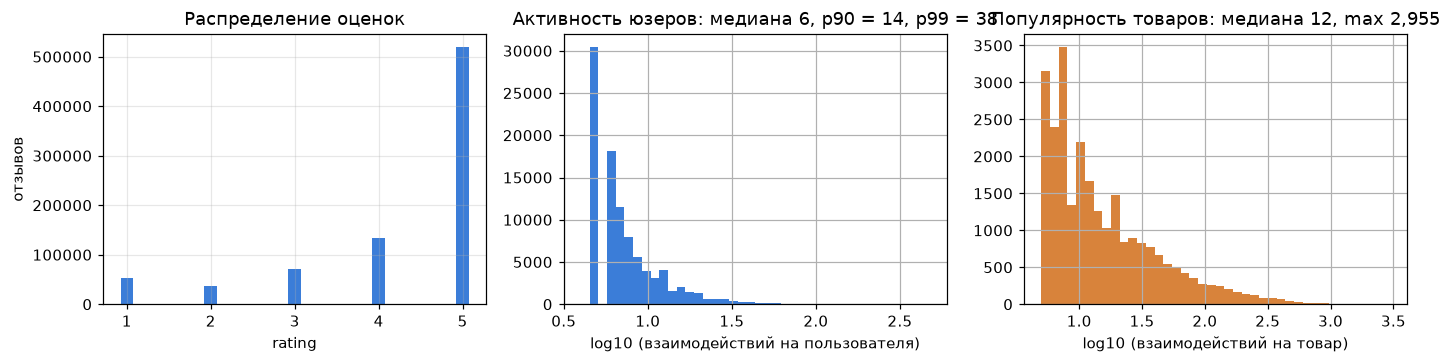

In [5]:
inter = pl.read_parquet("data/processed/interactions.parquet")
meta = pl.read_parquet("data/processed/items_meta.parquet")

print(f"Взаимодействий: {inter.height:,}; пользователей: {inter['user_idx'].n_unique():,}; товаров: {inter['item_idx'].n_unique():,}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

r_cnt = inter.group_by("rating").len().sort("rating")
axes[0].bar(r_cnt["rating"], r_cnt["len"], width=0.15, color="#3b7dd8")
axes[0].set_title("Распределение оценок")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("отзывов")
axes[0].grid(True, alpha=0.3)

u_deg = inter.group_by("user_idx").len()
u_vals = u_deg["len"].to_numpy()
u_q = np.quantile(u_vals, [0.1, 0.5, 0.9, 0.99])
axes[1].hist(np.log10(u_vals), bins=40, color="#3b7dd8")
axes[1].set_title(f"Активность юзеров: медиана {u_q[1]:.0f}, p90 = {u_q[2]:.0f}, p99 = {u_q[3]:.0f}")
axes[1].set_xlabel("log10 (взаимодействий на пользователя)")

i_deg = inter.group_by("item_idx").len()
i_vals = i_deg["len"].to_numpy()
axes[2].hist(np.log10(i_vals), bins=40, color="#d8833b")
axes[2].set_title(f"Популярность товаров: медиана {np.median(i_vals):.0f}, max {i_vals.max():,}")
axes[2].set_xlabel("log10 (взаимодействий на товар)")

fig.tight_layout()
plt.show()

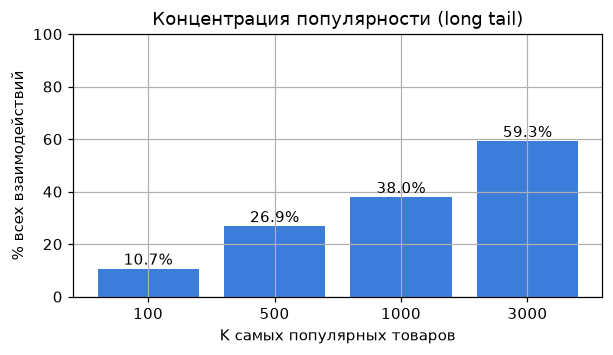

Товаров с >= 10 взаимодействий в train: 11,301 (вселенная C при лимите 25 000)


In [6]:
i_deg_sorted = inter.group_by("item_idx").len().sort("len", descending=True)
tot = float(i_deg_sorted["len"].sum())
ks = [100, 500, 1000, 3000]
cov = [float(i_deg_sorted[:k]["len"].sum() / tot) for k in ks]

plt.figure(figsize=(6.2, 3.1))
plt.bar([str(k) for k in ks], [c * 100 for c in cov], color="#3b7dd8")
plt.xlabel("K самых популярных товаров")
plt.ylabel("% всех взаимодействий")
plt.title("Концентрация популярности (long tail)")
for i, (k, c) in enumerate(zip(ks, cov)):
    plt.text(i, c * 100 + 1.5, f"{c*100:.1f}%", ha="center")
plt.ylim(0, 100)
plt.show()

thr = 10
train_degrees = inter.filter(pl.col("split") == "train").group_by("item_idx").len()
n_cand_thresh = train_degrees.filter(pl.col("len") >= thr).height
print(f"Товаров с >= {thr} взаимодействий в train: {n_cand_thresh:,} (вселенная C при лимите 25 000)")

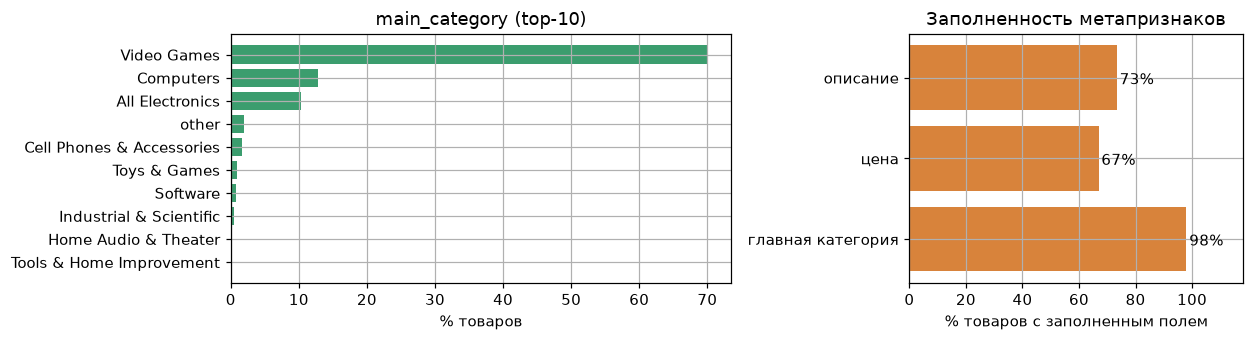

Цена: медиана 29.91 $; длина описания: медиана 410 символов; длина названия: медиана 51


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})

cat_top = meta.group_by("cat_main").len().sort("len", descending=True).head(10)
axes[0].barh(
    cat_top["cat_main"].to_list()[::-1],
    (cat_top["len"] / meta.height * 100).to_list()[::-1],
    color="#3b9d6e",
)
axes[0].set_xlabel("% товаров")
axes[0].set_title("main_category (top-10)")

price_share = float(meta["price"].is_finite().fill_null(False).mean())
desc_share = float((meta["desc_len"] > 0).mean())
cat_share = float((meta["cat_main"] != "other").mean())
bars = axes[1].barh(["главная категория", "цена", "описание"], [cat_share*100, price_share*100, desc_share*100], color="#d8833b")
axes[1].set_xlabel("% товаров с заполненным полем")
axes[1].set_title("Заполненность метапризнаков")
for b in bars:
    axes[1].text(b.get_width() + 1, b.get_y() + 0.32, f"{b.get_width():.0f}%")
axes[1].set_xlim(0, 118)
fig.tight_layout()
plt.show()

print(f"Цена: медиана {meta['price'].filter(meta['price'].is_finite()).median():.2f} $; длина описания: медиана {meta['desc_len'].median():.0f} символов; длина названия: медиана {meta['title_len'].median():.0f}")

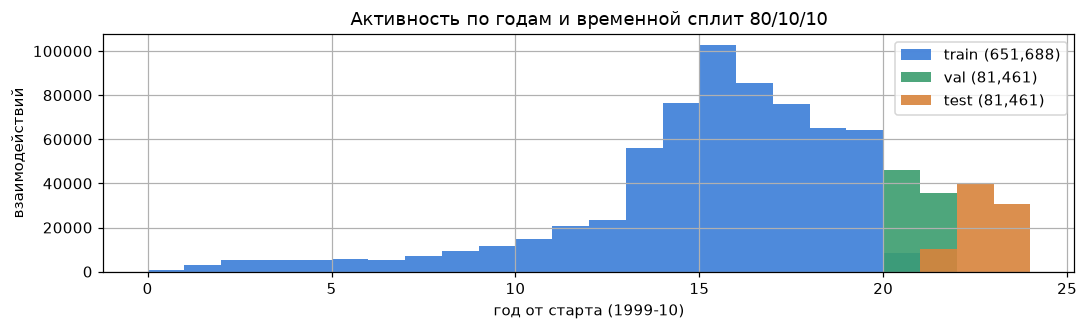

Датасет: Sat Oct 23 01:43:15 1999 … Sat Sep  2 21:14:28 2023 (24 года)


In [8]:
years = (inter["ts"].to_numpy() - summary["ts_min"]) / (365.25 * 86_400)
bins = np.arange(0, years.max() + 1)
fig, ax = plt.subplots(figsize=(10, 3.1))
colors = {"train": "#3b7dd8", "val": "#3b9d6e", "test": "#d8833b"}
for sp in ["train", "val", "test"]:
    vals = years[inter["split"].to_numpy() == sp]
    ax.hist(vals, bins=bins, alpha=0.9, label=f"{sp} ({len(vals):,})", color=colors[sp])
ax.set_xlabel("год от старта (1999-10)")
ax.set_ylabel("взаимодействий")
ax.set_title("Активность по годам и временной сплит 80/10/10")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Датасет: {time.ctime(summary['ts_min'])} … {time.ctime(summary['ts_max'])} (24 года)")

## 4. Протокол оценки

* Временное разбиение 80/10/10 по квантилям timestamp: первые 80% отзывов — train,
  следующие 10% — val, последние 10% — test.
* Множество кандидатов `C` одинаково для всех моделей: товары с не менее чем
  10 взаимодействиями в train. Для ограничения памяти EASE оставляем не более
  25 000 самых активных товаров; в этом прогоне |C| ≈ 11 301.
* Релевантные товары — товары из отзывов пользователя в val/test, входящие в `C`.
  Оцениваем только пользователей с историей в train и хотя бы одним релевантным
  товаром в соответствующем окне. Список пользователей общий для всех моделей.
* Перед выбором top-10 скрываем товары из истории train, присваивая им скор −∞.
* Время рекомендации `t_rec` для FM с кварталом и timeSVD++: конец train при подборе
  параметров, начало test при финальной оценке. Значения записаны в `summary.json`.
* Основная метрика для подбора параметров и сравнения — NDCG@10. Также считаем
  HR@10 (долю пользователей с хотя бы одним попаданием в top-10), MRR@10, MAP@10,
  Recall@10 и Coverage@10 (долю товаров из `C`, попавших в рекомендации).
* Нормировка IDCG/AP — по `min(10, |rel|)`.


In [8]:
import numpy as np

def _dcg_gains(k: int) -> np.ndarray:
    return 1.0 / np.log2(np.arange(2, k + 2))

def user_metrics(top_items: np.ndarray, rel_items: np.ndarray, k: int) -> dict[str, float]:
    if len(rel_items) == 0:
        return {m: 0.0 for m in ('hr', 'ndcg', 'mrr', 'map', 'recall')}
    hits = np.isin(top_items, rel_items, assume_unique=True)
    n_hits = int(hits.sum())
    mrr = 0.0
    if n_hits:
        first = int(np.argmax(hits))
        mrr = 1.0 / (first + 1)
    denom = min(k, len(rel_items))
    dcg = float(np.dot(hits, _dcg_gains(len(top_items))))
    idcg = float(np.sum(_dcg_gains(denom)))
    prec_cum = np.cumsum(hits) / np.arange(1, len(top_items) + 1)
    ap = float(np.dot(prec_cum, hits) / denom)
    return {'hr': n_hits / len(rel_items), 'ndcg': dcg / idcg, 'mrr': mrr, 'map': ap, 'recall': n_hits / min(len(rel_items), len(top_items))}

def topk_from_scores(scores: np.ndarray, k: int) -> np.ndarray:
    part = np.argpartition(scores, -k, axis=1)[:, -k:]
    part_scores = np.take_along_axis(scores, part, axis=1)
    order = np.argsort(-part_scores, axis=1, kind='stable')
    return np.take_along_axis(part, order, axis=1)

def batch_metrics(top_items: np.ndarray, rel_sets: dict[int, np.ndarray], uids: np.ndarray, k: int) -> dict[str, float]:
    acc = {m: 0.0 for m in ('hr', 'ndcg', 'mrr', 'map', 'recall')}
    for row, uid in enumerate(uids):
        rel = rel_sets.get(int(uid))
        if rel is None:
            continue
        m = user_metrics(top_items[row], rel, k)
        for key, value in m.items():
            acc[key] += value
    n = max(1, sum((1 for u in uids if int(u) in rel_sets)))
    return {key: value / n for key, value in acc.items()}

In [9]:
import time
from dataclasses import dataclass
import numpy as np
METRIC_KEYS = ('hr', 'ndcg', 'mrr', 'map', 'recall')

@dataclass
class EvalSet:
    users: np.ndarray
    rel: dict[int, np.ndarray]

    def sample_users(self, n: int, seed: int) -> 'EvalSet':
        if n and n < len(self.users):
            rng = np.random.default_rng(seed)
            pick = np.sort(rng.permutation(len(self.users))[:int(n)])
            users = self.users[pick]
            return EvalSet(users.astype(np.int32), {int(u): self.rel[int(u)] for u in users})
        return self

def build_eval_set(user: np.ndarray, item: np.ndarray, exp: ExpData) -> EvalSet:
    ok = (exp.cand_pos[item] >= 0) & np.isin(user, np.unique(exp.train_u))
    u, i = (user[ok], item[ok])
    return EvalSet(np.unique(u).astype(np.int32), compress_rel_sets(u, i))

def _seen_positions(exp: ExpData, uids: np.ndarray) -> list[np.ndarray]:
    out = []
    rows = exp.X[uids]
    indptr, indices = (rows.indptr, rows.indices)
    for b in range(len(uids)):
        items = indices[indptr[b]:indptr[b + 1]].astype(np.int64)
        pos = exp.cand_pos[items]
        out.append(pos[pos >= 0])
    return out

class EvalResult:

    def __init__(self, metrics: dict, n_users: int, eval_s: float, top_items: np.ndarray, uids: np.ndarray):
        self.metrics = metrics
        self.n_users = n_users
        self.eval_s = eval_s
        self.top_items = top_items
        self.uids = uids

def evaluate_model(model, exp: ExpData, eval_set: EvalSet, k: int=10, chunk_users: int=2048) -> EvalResult:
    t0 = time.perf_counter()
    acc = {m: 0.0 for m in METRIC_KEYS}
    n_eval = 0
    top_parts: list[np.ndarray] = []
    uid_parts: list[np.ndarray] = []
    for start in range(0, len(eval_set.users), chunk_users):
        uids = eval_set.users[start:start + chunk_users]
        scores = model.score_candidates(uids, exp.cand_items)
        for b, pos in enumerate(_seen_positions(exp, uids)):
            if len(pos):
                scores[b, pos] = -np.inf
        top_pos = topk_from_scores(scores, k)
        top_items = exp.cand_items[top_pos.astype(np.int64)]
        m = batch_metrics(top_items, eval_set.rel, uids, k)
        for key in METRIC_KEYS:
            acc[key] += m[key] * len(uids)
        n_eval += len(uids)
        top_parts.append(top_items.astype(np.int32))
        uid_parts.append(uids.astype(np.int32))
    metrics = {key: value / max(1, n_eval) for key, value in acc.items()}
    if top_parts:
        metrics['coverage'] = float(len(np.unique(np.concatenate(top_parts)))) / len(exp.cand_items)
    return EvalResult(metrics, n_eval, time.perf_counter() - t0, np.concatenate(top_parts), np.concatenate(uid_parts))

def topk_for_user(model, exp: ExpData, uid: int, k: int=10) -> np.ndarray:
    scores = model.score_candidates(np.array([uid], dtype=np.int32), exp.cand_items)
    seen = exp.X.indices[exp.X.indptr[uid]:exp.X.indptr[uid + 1]].astype(np.int64)
    pos = exp.cand_pos[seen]
    pos = pos[pos >= 0]
    if len(pos):
        scores[0, pos] = -np.inf
    return exp.cand_items[topk_from_scores(scores, k)[0].astype(np.int64)]

In [10]:
exp = load_experiment(
    "data/processed",
    cand_item_min_interactions=10,
    cand_max_items=25_000,
)
val_set = build_eval_set(exp.val_user, exp.val_item, exp)
test_set = build_eval_set(exp.test_user, exp.test_item, exp)

bounds = summary["split_time_bounds"]
t_train_end, t_test_start = bounds["train"][1], bounds["test"][0]

print(f"users={exp.n_users:,}  items={exp.n_items:,}  train={len(exp.train_u):,}  |C|={len(exp.cand_items):,}")
print(f"val: {len(exp.val_users):,} пользователей с позитивами в C (пар {len(exp.val_item):,})")
print(f"test: {len(exp.test_users):,} пользователей с позитивами в C (пар {len(exp.test_item):,})")
print(f"t_train_end={time.ctime(t_train_end)}; t_test_start={time.ctime(t_test_start)}")

users=94,766  items=25,614  train=651,688  |C|=11,301
val: 16,757 пользователей с позитивами в C (пар 30,297)
test: 6,767 пользователей с позитивами в C (пар 9,941)
t_train_end=Tue Dec 10 06:53:18 2019; t_test_start=Sat Jul 10 00:13:32 2021


## 5. Модели и пространство гиперпараметров

Реализации моделей приведены ниже.

* **Item-KNN**: item-item косинус с shrinkage `sim(c,j) = f(c,j)/(√(n_c·n_j)+γ)`;
  score(u,c) = Σ_{j∈N(u)} sim(c,j); соседи топ-K.
* **EASE** (Steck 2019): `P=(XᵀX+λI)⁻¹`, `B=I−P·diag(1/diag(P))`, score(u)=X_u·B.
* **ALS**: явная постановка `μ+b_u+b_i+pᵤᵀqᵢ` (биасы аналитические со shrinkage, факторы —
  ridge-решения на остатках); неявная (Hu–Koren–Volinsky): уверенность `c=1+αr`, таргет `t=1`,
  скор `pᵤᵀqᵢ`. Общее ridge-ядро: `A=Σw·zzᵀ+λI, b=Σw·t·z` (батчевые решения через torch.linalg.solve, f64).
* **FM** (Rendle 2010): `y(x)=w₀+Σw_f·x_f+½[(Σv_f)²−Σ‖v_f‖²]` с σ-trick за O(F·d).
  Метапризнаки, доступные **в момент рекомендации**: item-side — item_id, категорийный путь,
  магазин, бакет цены, бакет длины описания, бакет длины названия; user-side — user_id,
  бакет активности, бакет средней оценки, любимая категория (агрегаты по train), квартал
  времени рекомендации. Функции потерь: **BPR** (основной; негатив из C) и MSE (вариант).
* **timeSVD++**: `r̂=μ+bᵢ(t)+b_u(t)+qᵢᵀ(p_u+|N(u)|^{-½}Σ_{j∈N(u)}y_j)`, где
  `b_i(t) = b_i + b_{i,Bin(t)}`, `b_u(t) = b_u + α_u·dev_u(t) + b_{u,Bin(t)}`,
  `dev_u(t)=sign(Δt)·|Δt|^(2/3)` (Δt в годах, от первого отзыва пользователя),
  бины 90/365 дней.

Пятая модель — timeSVD++. Сравнение с ALS приведено в разделе 7.

In [12]:
grids = {'random': [{}],
 'popularity': [{}],
 'itemknn': [{'shrinkage': 10, 'topk': 100},
             {'shrinkage': 100, 'topk': 100},
             {'shrinkage': 500, 'topk': 100}],
 'ease': [{'lam': 500}, {'lam': 1500}, {'lam': 4000}],
 'als': [{'f': 32, 'iterations': 8, 'lam': 0.05, 'lam_b': 20, 'implicit': False},
         {'f': 32, 'iterations': 8, 'lam': 1.0, 'lam_b': 20, 'implicit': False},
         {'f': 32, 'iterations': 15, 'lam': 1.0, 'implicit': True, 'alpha': 0.0},
         {'f': 64, 'iterations': 15, 'lam': 5.0, 'implicit': True, 'alpha': 0.0},
         {'f': 64, 'iterations': 15, 'lam': 10.0, 'implicit': True, 'alpha': 0.0},
         {'f': 32, 'iterations': 15, 'lam': 1.0, 'implicit': True, 'alpha': 2.0}],
 'fm': [{'objective': 'bpr',
         'dim': 16,
         'lr': 0.01,
         'epochs': 8,
         'batch_size': 8192,
         'eval_every': 2,
         'feature_set': 'full',
         'wd': 0.0001},
        {'objective': 'bpr',
         'dim': 32,
         'lr': 0.02,
         'epochs': 6,
         'batch_size': 8192,
         'eval_every': 2,
         'feature_set': 'full',
         'wd': 0.0001},
        {'objective': 'bpr',
         'dim': 16,
         'lr': 0.03,
         'epochs': 8,
         'batch_size': 8192,
         'eval_every': 2,
         'feature_set': 'full',
         'wd': 0.0001},
        {'objective': 'mse',
         'dim': 16,
         'lr': 0.02,
         'epochs': 10,
         'batch_size': 8192,
         'eval_every': 2,
         'feature_set': 'full'}],
 'fm_ids': [{'objective': 'bpr',
             'dim': 16,
             'lr': 0.01,
             'epochs': 8,
             'batch_size': 8192,
             'eval_every': 2,
             'feature_set': 'ids',
             'wd': 0.0001}],
 'timesvdpp': [{'f': 32,
                'lr': 0.005,
                'epochs': 14,
                'bin_days': 90,
                'batch_size': 8192,
                'eval_every': 2},
               {'f': 32,
                'lr': 0.005,
                'epochs': 14,
                'bin_days': 365,
                'batch_size': 8192,
                'eval_every': 2}]}

seed = SEED
K, CHUNK, PROBE = 10, 2048, 8000
grid_rows = [{'модель': name, **point} for name, grid in grids.items() for point in grid]
display(pl.DataFrame(grid_rows))

модель,shrinkage,topk,lam,f,iterations,lam_b,implicit,alpha,objective,dim,lr,epochs,batch_size,eval_every,feature_set,wd,bin_days
str,i64,i64,f64,i64,i64,i64,bool,f64,str,i64,f64,i64,i64,i64,str,f64,i64
"""random""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""popularity""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""itemknn""",10,100,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""itemknn""",100,100,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""itemknn""",500,100,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""fm""",null,null,null,null,null,null,null,null,"""bpr""",16,0.03,8,8192,2,"""full""",0.0001,null
"""fm""",null,null,null,null,null,null,null,null,"""mse""",16,0.02,10,8192,2,"""full""",null,null
"""fm_ids""",null,null,null,null,null,null,null,null,"""bpr""",16,0.01,8,8192,2,"""ids""",0.0001,null


## 6. Подбор гиперпараметров и обучение

Гиперпараметры выбираются по NDCG@10 на фиксированной выборке 8 000 val-пользователей.
Внутри обучения FM и timeSVD++ для выбора эпохи используется отдельная выборка
до 8 000 val-пользователей с seed текущей конфигурации.
Финальная оценка — на всех подходящих test-пользователях в момент начала test.


### Признаки FM

In [13]:
from dataclasses import dataclass
import numpy as np

def _quantile_bins(values: np.ndarray, n_bins: int=10) -> np.ndarray:
    values = np.asarray(values, dtype=np.float64)
    qs = np.linspace(0.0, 1.0, n_bins + 2)[1:-1]
    edges = np.unique(np.quantile(values, qs))
    return np.searchsorted(edges, values, side='right').astype(np.int32)

def _quantile_bins_missing(values: np.ndarray, n_bins: int=10, missing_id: int | None=None):
    missing_id = n_bins if missing_id is None else missing_id
    ok = np.isfinite(values)
    ids = np.full(len(values), missing_id, dtype=np.int32)
    if ok.any():
        edges = np.unique(np.quantile(values[ok], np.linspace(0.0, 1.0, n_bins + 2)[1:-1]))
        ids[ok] = np.searchsorted(edges, values[ok], side='right').astype(np.int32)
    return (ids, missing_id + 1)

def quarter_of_ts(ts: np.ndarray) -> np.ndarray:
    months = ts.astype('datetime64[s]').astype('datetime64[M]').astype(np.int64) % 12
    return (months // 3).astype(np.int8)

@dataclass
class FeatureTables:
    user_fields: dict[str, np.ndarray]
    item_fields: dict[str, np.ndarray]
    user_side: list[str]
    item_side: list[str]
    vocabs: dict[str, int]

    def batch_user(self, uids: np.ndarray, ts: np.ndarray) -> np.ndarray:
        cols = []
        for name in self.user_side:
            cols.append(quarter_of_ts(ts) if name == 'quarter' else self.user_fields[name][uids])
        return np.stack(cols, axis=1).astype(np.int64)

    def batch_item(self, items: np.ndarray) -> np.ndarray:
        cols = [self.item_fields[name][items] for name in self.item_side]
        return np.stack(cols, axis=1).astype(np.int64)

    def with_fields(self, user_side: list[str], item_side: list[str]) -> 'FeatureTables':
        vocabs = {f: self.vocabs[f] for f in user_side + item_side}
        return FeatureTables(self.user_fields, self.item_fields, user_side, item_side, vocabs)

def _topk_categorical(strings: np.ndarray, top: int) -> tuple[np.ndarray, int]:
    uniq = np.unique(strings)
    codes = np.searchsorted(uniq, strings).astype(np.int32)
    counts = np.bincount(codes, minlength=len(uniq))
    if len(uniq) > top:
        keep_ids = np.argsort(-counts, kind='stable')[:top]
        keep = keep_ids
    else:
        keep = np.arange(len(uniq))
    remap = np.full(len(uniq), len(keep), dtype=np.int32)
    remap[keep.astype(np.int64)] = np.arange(len(keep), dtype=np.int64)
    return (remap[codes], len(keep) + 1)

def build_feature_tables(exp, store_top: int=120, cat_top: int=200) -> FeatureTables:
    from scipy import sparse
    meta = exp.items_meta
    item_fields: dict[str, np.ndarray] = {}
    vocabs: dict[str, int] = {}
    item_fields['item'] = np.arange(exp.n_items, dtype=np.int32)
    vocabs['item'] = exp.n_items
    cat_str = meta['cat_path'].fill_null('other').to_numpy().astype('U')
    cat_ids, n_cat = _topk_categorical(cat_str, cat_top)
    item_fields['cat'] = cat_ids
    vocabs['cat'] = n_cat
    store_str = meta['store'].fill_null('').to_numpy().astype('U')
    store_str = np.where(store_str == '', 'other', store_str)
    store_ids, n_store = _topk_categorical(store_str, store_top)
    item_fields['store'] = store_ids
    vocabs['store'] = n_store
    price = meta['price'].to_numpy().astype(np.float64)
    price_b, n_price = _quantile_bins_missing(price, 10)
    item_fields['price_b'] = price_b
    vocabs['price_b'] = n_price
    desc_len = meta['desc_len'].to_numpy().astype(np.float64)
    desc_b, n_desc = _quantile_bins_missing(np.where(desc_len > 0, desc_len, np.nan), 10)
    item_fields['desc_b'] = desc_b
    vocabs['desc_b'] = n_desc
    title_len = meta['title_len'].to_numpy().astype(np.float64)
    title_b, n_title = _quantile_bins_missing(title_len, 10)
    item_fields['title_b'] = title_b
    vocabs['title_b'] = n_title
    user_fields: dict[str, np.ndarray] = {}
    user_fields['user'] = np.arange(exp.n_users, dtype=np.int32)
    vocabs['user'] = exp.n_users
    counts = np.asarray(exp.X.sum(axis=1)).astype(np.float64).ravel()
    cnt_b = _quantile_bins(counts, 10)
    user_fields['u_cnt_b'] = cnt_b
    vocabs['u_cnt_b'] = int(cnt_b.max()) + 1
    r_sum = np.asarray(exp.R.sum(axis=1)).ravel().astype(np.float64)
    mean_r = np.where(counts > 0, r_sum / np.maximum(counts, 1.0), np.nan)
    mean_r_b, n_mean = _quantile_bins_missing(mean_r, 10)
    user_fields['u_rating_b'] = mean_r_b
    vocabs['u_rating_b'] = n_mean
    n_cat_ids = int(cat_ids.max()) + 1
    rows_rep = np.repeat(np.arange(exp.n_users, dtype=np.int64), np.diff(exp.X.indptr))
    hist = np.zeros((exp.n_users, n_cat_ids), dtype=np.int16)
    np.add.at(hist, (rows_rep, cat_ids[exp.X.indices].astype(np.int64)), 1)
    u_fav = hist.argmax(axis=1).astype(np.int32)
    user_fields['u_fav_cat'] = u_fav
    vocabs['u_fav_cat'] = int(u_fav.max()) + 1
    user_side = ['user', 'u_cnt_b', 'u_rating_b', 'u_fav_cat', 'quarter']
    item_side = ['item', 'cat', 'store', 'price_b', 'desc_b', 'title_b']
    vocabs['quarter'] = 4
    return FeatureTables(user_fields, item_fields, user_side, item_side, vocabs)

### Базовые модели

In [14]:
import numpy as np

class Popularity:
    name = 'popularity'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        self._cnt = np.asarray(exp.X[:, exp.cand_items].sum(axis=0)).ravel().astype(np.float32)

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        return np.tile(self._cnt[None, :], (len(uids), 1))

    def history(self):
        return None

class RandomModel:
    name = 'random'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        self._rng = np.random.default_rng(seed)
        self._c_size = len(exp.cand_items)

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        return self._rng.random((len(uids), self._c_size), dtype=np.float32)

    def history(self):
        return None

### Item-KNN

In [15]:
import numpy as np
from scipy import sparse

class ItemKNN:
    name = 'itemknn'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        gamma = float(params.get('shrinkage', 50.0))
        topk = int(params.get('topk', 100))
        C = exp.cand_items.astype(np.int64)
        Xc = exp.X[:, C]
        S = (Xc.T @ exp.X).tocoo()
        n_c = np.asarray(Xc.sum(axis=0)).ravel().astype(np.float64)
        n_j = np.asarray(exp.X.sum(axis=0)).ravel().astype(np.float64)
        norm = np.sqrt(n_c[S.row.astype(np.int64)]) * np.sqrt(n_j[S.col.astype(np.int64)])
        sim = S.data / (norm + gamma)
        sim[S.row.astype(np.int64) == S.col.astype(np.int64)] = 0.0
        keep = sim > 0
        rows, cols, vals = (S.row[keep].astype(np.int64), S.col[keep].astype(np.int64), sim[keep])
        order = np.lexsort((cols, rows))
        rows, cols, vals = (rows[order], cols[order], vals[order])
        row_bounds = np.searchsorted(rows, np.arange(S.shape[0] + 1))
        out_r, out_c, out_v = ([], [], [])
        for r in range(S.shape[0]):
            lo, hi = (int(row_bounds[r]), int(row_bounds[r + 1]))
            if hi == lo:
                continue
            if hi - lo > topk:
                part = lo + np.argpartition(vals[lo:hi], -topk)[-topk:]
            else:
                part = np.arange(lo, hi)
            out_r.append(cols[part])
            out_c.append(np.full(part.shape, r, dtype=np.int64))
            out_v.append(vals[part])
        j_rows = np.concatenate(out_r) if out_r else np.array([], dtype=np.int64)
        c_cols = np.concatenate(out_c) if out_c else np.array([], dtype=np.int64)
        j_vals = np.concatenate(out_v).astype(np.float32) if out_r else np.array([], dtype=np.float32)
        self._S_T = sparse.csr_matrix((j_vals, (j_rows, c_cols)), shape=(exp.n_items, len(C)), dtype=np.float32)
        self._c_size = len(C)
        self._X = exp.X

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        Xu = exp_sparse_rows(self._X, uids)
        scores = (Xu @ self._S_T).toarray()
        return scores.astype(np.float32, copy=False)

    def history(self):
        return None

def exp_sparse_rows(X: sparse.csr_matrix, uids: np.ndarray) -> sparse.csr_matrix:
    return X[uids]

### EASE

In [16]:
import numpy as np
from scipy import sparse

class EASE:
    name = 'ease'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        lam = float(params.get('lam', 500.0))
        C = exp.cand_items.astype(np.int64)
        Xc = exp.X[:, C]
        Xc = sparse.csr_matrix(Xc, dtype=np.float64)
        G = (Xc.T @ Xc).toarray()
        G[np.diag_indices_from(G)] += lam
        P = np.linalg.solve(G, np.eye(len(C), dtype=np.float64))
        diag = np.diagonal(P)
        B = -P / diag[np.newaxis, :]
        B[np.diag_indices_from(B)] = 0.0
        self._B = B.astype(np.float32)
        self._Xc = sparse.csr_matrix(Xc, dtype=np.float32)

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        out = self._Xc[uids] @ self._B
        return out if isinstance(out, np.ndarray) else out.toarray()

    def history(self):
        return None

### ALS

In [17]:
import numpy as np
import torch

def _index_pairs(primary, secondary, arrays, n_primary):
    order = np.lexsort((secondary, primary))
    counts = np.bincount(primary, minlength=n_primary)
    indptr = np.concatenate([[0], np.cumsum(counts)]).astype(np.int64)
    indices = secondary[order].astype(np.int32)
    return (indptr, indices, [np.ascontiguousarray(a[order], dtype=np.float32) for a in arrays])

def _pack_rows(indptr, indices, datas, u0: int, u1: int, wmax: int):
    deg = np.minimum(indptr[u0 + 1:u1 + 1] - indptr[u0:u1], wmax)
    deg = deg.astype(np.int64)
    bf = len(deg)
    total_valid = int(deg.sum())
    local = np.arange(total_valid, dtype=np.int64) - np.repeat(np.cumsum(deg) - deg, deg)
    src = np.repeat(indptr[u0:u1], deg) + local
    tgt = np.repeat(np.arange(bf, dtype=np.int64) * wmax, deg) + local
    items_pad = np.zeros(bf * wmax, dtype=np.int32)
    mask = np.zeros(bf * wmax, dtype=np.float32)
    items_pad[tgt] = indices[src]
    mask[tgt] = 1.0
    packed = []
    for data in datas:
        vals_pad = np.zeros(bf * wmax, dtype=np.float32)
        vals_pad[tgt] = data[src]
        packed.append(vals_pad.reshape(bf, wmax))
    return (items_pad.reshape(bf, wmax), packed, mask.reshape(bf, wmax))

def _als_solve_batched(A: np.ndarray, b: np.ndarray) -> np.ndarray:
    A_t = torch.from_numpy(np.ascontiguousarray(A, dtype=np.float64))
    b_t = torch.from_numpy(np.ascontiguousarray(b, dtype=np.float64))
    return torch.linalg.solve(A_t, b_t).numpy().astype(np.float32)

class ALS:
    name = 'als'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        f = int(params.get('f', 32))
        iterations = int(params.get('iterations', 8))
        lam = float(params.get('lam', 0.05))
        lam_b = float(params.get('lam_b', 20.0))
        implicit = bool(params.get('implicit', False))
        alpha = float(params.get('alpha', 0.0))
        W_max, I_max = (64, 1024)
        u, i, r = (exp.train_u, exp.train_i, exp.train_r.astype(np.float32))
        n_users, n_items = (exp.n_users, exp.n_items)
        if implicit:
            mu = None
            self._mu, self._b_u, self._b_i = (0.0, None, None)
            conf = (1.0 + alpha * r).astype(np.float32)
            w_data, t_data = (conf, np.ones_like(conf))
        else:
            mu = float(r.mean())
            n_i = np.bincount(i, minlength=n_items).astype(np.float32)
            b_i = np.bincount(i, weights=r - mu, minlength=n_items) / (n_i + lam_b)
            res = r - mu - b_i[i]
            n_u = np.bincount(u, minlength=n_users).astype(np.float32)
            b_u = np.bincount(u, weights=res, minlength=n_users) / (n_u + lam_b)
            e = (r - mu - b_u[u] - b_i[i]).astype(np.float32)
            self._mu, self._b_u, self._b_i = (mu, b_u, b_i)
            w_data, t_data = (np.ones_like(e), e)
        u64, i64 = (u.astype(np.int64), i.astype(np.int64))
        us_ptr, us_idx, (us_w, us_t) = _index_pairs(u64, i64, [w_data, t_data], n_users)
        is_ptr, is_idx, (is_w, is_t) = _index_pairs(i64, u64, [w_data, t_data], n_items)
        rng = np.random.default_rng(seed)
        self._f = f
        P = (rng.standard_normal((n_users, f)) * 0.05).astype(np.float32)
        Q = (rng.standard_normal((n_items, f)) * 0.05).astype(np.float32)
        hist_loss = []
        n_probe = min(200000, len(r))
        probe = np.random.default_rng(seed + 1).choice(len(r), n_probe, replace=False)
        pu, pi, pr, pw = (u[probe], i[probe], r[probe], w_data[probe])
        eye = lam * np.eye(f, dtype=np.float32)
        for it in range(iterations):
            for u0 in range(0, n_users, 16384):
                u1 = min(u0 + 16384, n_users)
                if us_ptr[u1] - us_ptr[u0] == 0:
                    continue
                items_pad, (w_pad, t_pad), mask = _pack_rows(us_ptr, us_idx, [us_w, us_t], u0, u1, W_max)
                deg_row = np.diff(us_ptr[u0:u1 + 1])
                big = np.flatnonzero(deg_row > W_max)
                Zm = Q[items_pad.ravel()].reshape(-1, W_max, f)
                w_zero = np.where(mask > 0, w_pad, 0.0)
                Zm = Zm * np.sqrt(np.maximum(w_zero, 0.0))[:, :, None]
                A = np.matmul(Zm.transpose(0, 2, 1), Zm)
                A += eye
                b = np.einsum('bwf,bw->bf', Zm / np.sqrt(np.maximum(w_zero, 1e-12))[:, :, None], w_zero * t_pad)
                for k in big:
                    k_row = u0 + k
                    lo, hi = (us_ptr[k_row], us_ptr[k_row + 1])
                    p1 = lo + min(int(deg_row[k]), W_max)
                    w_tail, t_tail = (us_w[p1:hi], us_t[p1:hi])
                    Wi = Q[us_idx[p1:hi]] * np.sqrt(w_tail)[:, None]
                    A[k] += Wi.T @ Wi
                    b[k] += Wi.T @ (t_tail * np.sqrt(w_tail))
                P[u0:u1] = _als_solve_batched(A, b)
            for j0 in range(0, n_items, 8192):
                j1 = min(j0 + 8192, n_items)
                if is_ptr[j1] - is_ptr[j0] == 0:
                    continue
                rows_pad, (w_pad, t_pad), mask = _pack_rows(is_ptr, is_idx, [is_w, is_t], j0, j1, I_max)
                deg_j = np.diff(is_ptr[j0:j1 + 1])
                big = np.flatnonzero(deg_j > I_max)
                Zm = P[rows_pad.ravel()].reshape(-1, I_max, f)
                w_zero = np.where(mask > 0, w_pad, 0.0)
                Zm = Zm * np.sqrt(np.maximum(w_zero, 0.0))[:, :, None]
                A = np.matmul(Zm.transpose(0, 2, 1), Zm)
                A += eye
                b = np.einsum('bwf,bw->bf', Zm / np.sqrt(np.maximum(w_zero, 1e-12))[:, :, None], w_zero * t_pad)
                for k in big:
                    k_col = j0 + k
                    lo, hi = (is_ptr[k_col], is_ptr[k_col + 1])
                    p1 = lo + min(int(deg_j[k]), I_max)
                    w_tail, t_tail = (is_w[p1:hi], is_t[p1:hi])
                    Pi = P[is_idx[p1:hi]] * np.sqrt(w_tail)[:, None]
                    A[k] += Pi.T @ Pi
                    b[k] += Pi.T @ (t_tail * np.sqrt(w_tail))
                Q[j0:j1] = _als_solve_batched(A, b)
            if implicit:
                pred = np.einsum('bf,bf->b', P[pu], Q[pi])
                loss = float(np.sqrt(np.sum(pw * (pred - 1.0) ** 2) / pw.sum()))
            else:
                pred = mu + self._b_u[pu] + self._b_i[pi] + np.einsum('bf,bf->b', P[pu], Q[pi])
                loss = float(np.sqrt(np.mean((pr - pred) ** 2)))
            hist_loss.append(loss)
        self._P, self._Q = (P, Q)
        self._implicit = implicit
        self._loss_history = hist_loss

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        scores = self._P[uids] @ self._Q[cand_items].T
        if not self._implicit:
            scores += (self._mu + self._b_u[uids])[:, None]
            scores += self._b_i[cand_items][None, :]
        return scores.astype(np.float32)

    def history(self):
        return {'loss': self._loss_history}

### FM

In [18]:
import numpy as np
import torch
import torch.nn as nn

class _FMNet(nn.Module):

    def __init__(self, fields: list[str], vocabs: dict[str, int], dim: int):
        super().__init__()
        self.fields = fields
        self.bias = nn.Parameter(torch.zeros(1))
        self.lin = nn.ModuleDict({f: nn.Embedding(vocabs[f], 1) for f in fields})
        self.vec = nn.ModuleDict({f: nn.Embedding(vocabs[f], dim) for f in fields})
        with torch.no_grad():
            for f in fields:
                self.lin[f].weight.zero_()
                nn.init.normal_(self.vec[f].weight, 0.0, 0.05)

    def forward(self, ids: torch.Tensor) -> torch.Tensor:
        lin = self.bias
        Vs = []
        for j, f in enumerate(self.fields):
            col = ids[:, j]
            lin = lin + self.lin[f](col).squeeze(1)
            Vs.append(self.vec[f](col))
        V = torch.stack(Vs, dim=1)
        sumv = V.sum(1)
        pair = 0.5 * ((sumv * sumv).sum(1) - (V * V).sum((1, 2)))
        return lin + pair

class FM:
    name = 'fm'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        torch.manual_seed(int(seed))
        ft = params.get('ft') or build_feature_tables(exp)
        if params.get('feature_set', 'full') == 'ids':
            ft = ft.with_fields(['user'], ['item'])
        val: EvalSet | None = params.get('val')
        val_s = val.sample_users(int(params.get('tune_eval_users', 8000)), seed) if val is not None else None
        dim = int(params.get('dim', 16))
        epochs = int(params.get('epochs', 20))
        lr = float(params.get('lr', 0.03))
        batch_size = int(params.get('batch_size', 8192))
        eval_every = int(params.get('eval_every', 2))
        objective = params.get('objective', 'bpr')
        wd = float(params.get('wd', 1e-06))
        cand = exp.cand_items.astype(np.int64)
        u, i, r, ts = (exp.train_u, exp.train_i, exp.train_r.astype(np.float32), exp.train_ts)
        n = len(u)
        self._default_t_rec = float(ts.max())
        self._t_rec = self._default_t_rec
        net = _FMNet(ft.user_side + ft.item_side, ft.vocabs, dim)
        opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
        loss_hist, val_hist = ([], [])
        best_ndcg, best_state = (-1.0, None)
        for epoch in range(epochs):
            if objective == 'bpr':
                rng_neg = np.random.default_rng(seed + 30000 + epoch)
            perm = np.random.default_rng(seed + 10000 + epoch).permutation(n)
            loss_sum, cnt_sum = (0.0, 0)
            for b0 in range(0, n, batch_size):
                idx = perm[b0:b0 + batch_size]
                ub = self._user_block(ft, u, ts, idx)
                if objective == 'bpr':
                    neg = cand[rng_neg.integers(0, len(cand), size=len(idx))]
                    dup = neg == i[idx]
                    if dup.any():
                        neg[dup] = cand[rng_neg.integers(0, len(cand), size=int(dup.sum()))]
                    ids_p = np.concatenate([ub, ft.batch_item(i[idx])], axis=1)
                    ids_n = np.concatenate([ub, ft.batch_item(neg)], axis=1)
                    sp, sn = (net(torch.from_numpy(ids_p)), net(torch.from_numpy(ids_n)))
                    loss = -torch.nn.functional.logsigmoid(sp - sn).mean()
                    loss_sum += float(loss.detach()) * len(idx)
                else:
                    ids = torch.from_numpy(np.concatenate([ub, ft.batch_item(i[idx])], axis=1))
                    rr = torch.from_numpy(r[idx])
                    pred = net(ids)
                    loss = ((pred - rr) ** 2).mean()
                    loss_sum += float(((pred - rr) ** 2).detach().sum())
                opt.zero_grad()
                loss.backward()
                opt.step()
                cnt_sum += len(idx)
            if objective == 'bpr':
                loss_hist.append(loss_sum / max(1, cnt_sum))
            else:
                loss_hist.append(float(np.sqrt(loss_sum / max(1, cnt_sum))))
            if val_s is not None and epoch % eval_every == 0:
                self._net, self._ft = (net, ft)
                self._clear_item_cache()
                res = evaluate_model(self, exp, val_s, chunk_users=4096)
                nd = float(res.metrics['ndcg'])
                val_hist.append(nd)
                if nd > best_ndcg:
                    best_ndcg = nd
                    best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        if best_state is not None:
            net.load_state_dict(best_state)
        self._net, self._ft = (net, ft)
        self._loss_hist, self._val_hist = (loss_hist, val_hist)
        self._objective = objective
        self._clear_item_cache()

    def _user_block(self, ft, u, ts, idx: np.ndarray) -> np.ndarray:
        uu = u[idx]
        return np.stack([ft.user_fields[name][uu] if name != 'quarter' else quarter_of_ts(ts[idx]) for name in ft.user_side], axis=1).astype(np.int64)

    def _clear_item_cache(self):
        self._Si = None
        self._item_base = None

    def _field_stats(self, ids: torch.Tensor, fields: list[str]):
        net = self._net
        Vs, lin = ([], 0.0)
        for j, f in enumerate(fields):
            col = ids[:, j]
            lin = lin + net.lin[f](col).squeeze(1)
            Vs.append(net.vec[f](col))
        V = torch.stack(Vs, dim=1)
        S = V.sum(1)
        sq = (V * V).sum((1, 2))
        pair = 0.5 * ((S * S).sum(1) - sq)
        return (S, lin, pair)

    def _item_stats(self, cand_items: np.ndarray):
        if self._Si is not None and self._Si.shape[0] == len(cand_items):
            return (self._Si, self._item_base)
        with torch.no_grad():
            ids_C = torch.from_numpy(self._ft.batch_item(cand_items))
            S_i, lin_i, pair_i = self._field_stats(ids_C, self._ft.item_side)
            self._Si = S_i.detach().numpy().astype(np.float32)
            self._item_base = (lin_i + pair_i).detach().numpy().astype(np.float32)
        return (self._Si, self._item_base)

    def set_t_rec(self, t_rec: float) -> None:
        self._t_rec = float(t_rec)

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        ft = self._ft
        t_rec = float(getattr(self, '_t_rec', getattr(self, '_default_t_rec', 0.0)))
        with torch.no_grad():
            ids_u = torch.from_numpy(np.stack([ft.user_fields[name][uids] if name != 'quarter' else quarter_of_ts(np.full(len(uids), t_rec)) for name in ft.user_side], axis=1).astype(np.int64))
            S_u, lin_u, pair_u = self._field_stats(ids_u, ft.user_side)
            S_i, item_base = self._item_stats(cand_items)
            dot = (S_u @ S_i.T).numpy()
            user_base = (lin_u + pair_u).detach().numpy().astype(np.float32)
            bias = float(self._net.bias.detach().numpy()[0])
        scores = bias + user_base[:, None] + item_base[None, :] + dot
        return scores.astype(np.float32)

    def history(self):
        key = 'loss' if getattr(self, '_objective', 'bpr') == 'bpr' else 'rmse'
        return {key: self._loss_hist, 'val_ndcg': self._val_hist}

### timeSVD++

In [19]:
import numpy as np
import torch

def _gen(seed: int) -> torch.Generator:
    g = torch.Generator()
    g.manual_seed(int(seed))
    return g

class TimeSVDPP:
    name = 'timesvdpp'

    def fit(self, exp, params: dict, seed: int=0) -> None:
        f = int(params.get('f', 32))
        epochs = int(params.get('epochs', 20))
        lr0 = float(params.get('lr', 0.05))
        reg = float(params.get('reg', 0.05))
        bin_days = int(params.get('bin_days', 90))
        batch_size = int(params.get('batch_size', 8192))
        eval_every = int(params.get('eval_every', 2))
        lr_decay = float(params.get('lr_decay', 0.97))
        pred_lo = float(params.get('pred_lo', 0.5))
        pred_hi = float(params.get('pred_hi', 5.5))
        val = params.get('val')
        val_s = val.sample_users(int(params.get('tune_eval_users', 8000)), seed) if val is not None else None
        u, i, r, ts = (exp.train_u, exp.train_i, exp.train_r.astype(np.float32), exp.train_ts)
        U, I = (exp.n_users, exp.n_items)
        self._default_t_rec = float(ts.max())
        t_min = float(ts.min())
        bin_len = float(bin_days * 86400.0)
        nb = int(np.ceil((ts.max() - t_min) / bin_len)) + 1
        bin_s = np.clip(((ts - t_min) / bin_len).astype(np.int64), 0, nb - 1)
        anchor = np.full(U, np.inf, dtype=np.float64)
        np.minimum.at(anchor, u.astype(np.int64), ts)
        anchor[np.isinf(anchor)] = t_min
        yr = (ts - anchor[u]) / (365.25 * 86400.0)
        dev_s = (np.sign(yr) * np.abs(yr) ** (2.0 / 3.0)).astype(np.float32)
        u_idx = torch.from_numpy(u.astype(np.int64))
        i_idx = torch.from_numpy(i.astype(np.int64))
        r_t = torch.from_numpy(r)
        dev_t = torch.from_numpy(dev_s)
        iflat_t = torch.from_numpy(i.astype(np.int64) * nb + bin_s)
        uflat_t = torch.from_numpy(u.astype(np.int64) * nb + bin_s)
        rng = np.random.default_rng(seed)
        mu_t = torch.tensor(float(r.mean()), dtype=torch.float32)
        bi = torch.zeros(I, dtype=torch.float32)
        bi_b = torch.zeros(I * nb, dtype=torch.float32)
        bu = torch.zeros(U, dtype=torch.float32)
        au = torch.zeros(U, dtype=torch.float32)
        bu_b = torch.zeros(U * nb, dtype=torch.float32)
        Q = torch.from_numpy((rng.standard_normal((I, f)) * 0.02).astype(np.float32))
        P = torch.from_numpy((rng.standard_normal((U, f)) * 0.02).astype(np.float32))
        Y = torch.from_numpy((rng.standard_normal((I, f)) * 0.02).astype(np.float32))
        X = exp.X.astype(np.float32).tocsr()
        deg = np.asarray(X.sum(axis=1)).astype(np.float32).ravel()
        inv_sqrt = (1.0 / np.sqrt(np.maximum(deg, 1.0))).astype(np.float32)
        inv_sqrt_t = torch.from_numpy(inv_sqrt)
        normY = (X.T @ inv_sqrt[:, None]).astype(np.float32).ravel()
        n = len(u)
        rmse_hist, val_hist = ([], [])
        best_ndcg, best_state, best_aux = (-1.0, None, None)
        good_state = None
        for epoch in range(epochs):
            lr = lr0 * lr_decay ** epoch
            perm = torch.randperm(n, generator=_gen(seed + 1000000 + epoch))
            prof = P + torch.from_numpy((X @ Y.numpy()).astype(np.float32)) * inv_sqrt_t[:, None]
            g_u = torch.zeros(U, f, dtype=torch.float32)
            sq_sum = 0.0
            for b0 in range(0, n, batch_size):
                sel = perm[b0:b0 + batch_size]
                bu_s, bi_s = (u_idx[sel], i_idx[sel])
                prof_u = prof[bu_s]
                pred = mu_t + bi[bi_s] + bi_b[iflat_t[sel]] + bu[bu_s] + au[bu_s] * dev_t[sel] + bu_b[uflat_t[sel]] + (Q[bi_s] * prof_u).sum(1)
                pred = pred.clamp(pred_lo, pred_hi)
                e = r_t[sel] - pred
                sq_sum += float((e * e).sum())
                mu_t += lr * float(e.mean())
                bi.index_add_(0, bi_s, lr * e)
                bi_b.index_add_(0, iflat_t[sel], lr * e)
                bu.index_add_(0, bu_s, lr * e)
                au.index_add_(0, bu_s, lr * e * dev_t[sel])
                bu_b.index_add_(0, uflat_t[sel], lr * e)
                Q.index_add_(0, bi_s, e[:, None] * prof_u * lr)
                P.index_add_(0, bu_s, e[:, None] * Q[bi_s] * lr)
                g_u.index_add_(0, bu_s, e[:, None] * Q[bi_s])
            Yg = (X.T @ (g_u.numpy() * inv_sqrt[:, None]).astype(np.float32)).astype(np.float32)
            act = normY > 0
            Ystep = np.clip(Yg[act] / normY[act, None].astype(np.float32), -3.0, 3.0)
            Y[act] += lr * torch.from_numpy(Ystep)
            decay = 1.0 - lr * reg
            for p in (bi, bi_b, bu, au, bu_b, Q, P):
                p.mul_(decay)
            emb_cap = float(params.get('emb_cap', 2.0))
            for p in (Q, P, Y):
                nrm = p.norm(dim=1)
                mult = torch.clamp(emb_cap / nrm.clamp_min(1e-08), max=1.0)
                p.mul_(mult[:, None])
            rmse_hist.append(float(np.sqrt(sq_sum / n)))
            if not np.isfinite(rmse_hist[-1]):
                print(f'  timesvdpp: non-finite RMSE at epoch {epoch}, stopping', flush=True)
                if good_state is not None:
                    params_state, aux = good_state
                    (mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y), (anchor, deg) = (params_state, aux)
                break
            good_state = (tuple((p.detach().clone() for p in (mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y))), (anchor, deg))
            if val_s is not None and epoch % eval_every == 0:
                self._freeze(mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y, anchor, t_min, bin_len, nb, deg, X)
                res = evaluate_model(self, exp, val_s, chunk_users=4096)
                nd = float(res.metrics['ndcg'])
                val_hist.append(nd)
                if nd > best_ndcg:
                    best_ndcg = nd
                    best_state = tuple((p.detach().clone() for p in (mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y)))
                    best_aux = (anchor.copy(), deg.copy())
        if best_state is not None:
            mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y = best_state
            anchor, deg = best_aux
        self._freeze(mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y, anchor, t_min, bin_len, nb, deg, X)
        self._rmse_hist, self._val_hist = (rmse_hist, val_hist)

    def _freeze(self, mu_t, bi, bi_b, bu, au, bu_b, Q, P, Y, anchor, t_min, bin_len, nb, deg, X):
        self._mu = mu_t
        self._bi, self._bi_b = (bi, bi_b)
        self._bu, self._au, self._bu_b = (bu, au, bu_b)
        self._Q, self._P, self._Y = (Q, P, Y)
        self._anchor, self._t_min = (anchor, t_min)
        self._bin_len, self._nb = (bin_len, nb)
        self._deg = deg
        self._X_np = X
        self._inv_sqrt = (1.0 / np.sqrt(np.maximum(deg, 1.0))).astype(np.float32)
        self._prof_cache = None

    def _profile(self):
        if self._prof_cache is None:
            self._prof_cache = self._P + torch.from_numpy((self._X_np @ self._Y.numpy()).astype(np.float32)) * torch.from_numpy(self._inv_sqrt)[:, None]
        return self._prof_cache

    def set_t_rec(self, t_rec: float) -> None:
        self._t_rec = float(t_rec)

    def score_candidates(self, uids: np.ndarray, cand_items: np.ndarray) -> np.ndarray:
        t_rec = float(getattr(self, '_t_rec', self._default_t_rec))
        prof = self._profile()
        c_idx = torch.from_numpy(cand_items.astype(np.int64))
        u_l = torch.from_numpy(uids.astype(np.int64))
        I, nb = (self._Q.shape[0], self._nb)
        bin_rec = int(np.floor((t_rec - self._t_min) / self._bin_len))
        if 0 <= bin_rec < nb:
            bi_b_slice = self._bi_b.view(I, nb)[:, bin_rec]
            bu_b_slice = self._bu_b.view(-1, nb)[:, bin_rec]
            b_c = self._bi[c_idx] + bi_b_slice[c_idx]
            user_extra = bu_b_slice[u_l]
        else:
            b_c = self._bi[c_idx]
            user_extra = torch.zeros(len(uids), dtype=torch.float32)
        ts_rec = torch.full((len(uids),), t_rec, dtype=torch.float32)
        anchor = torch.from_numpy(self._anchor[uids].astype(np.float32))
        yr = (ts_rec - anchor) / (365.25 * 86400.0)
        dev = torch.sign(yr) * yr.abs() ** (2.0 / 3.0)
        dev = torch.nan_to_num(dev, nan=0.0, posinf=0.0, neginf=0.0)
        user_base = self._bu[u_l] + self._au[u_l] * dev + user_extra
        dot = (prof[u_l] @ self._Q[c_idx].T).numpy()
        scores = float(self._mu) + b_c.numpy()[None, :] + user_base.numpy()[:, None] + dot
        return scores.astype(np.float32)

    def history(self):
        return {'rmse': self._rmse_hist, 'val_ndcg': self._val_hist}

### Обучение и оценка

In [20]:
ft = build_feature_tables(exp)


probe = val_set.sample_users(PROBE, seed)  # фиксированный сэмпл val-пользователей

RUN: dict = {}  # name -> {"grid_val": [...], "params": ..., "val": ..., "test": ..., "history": ...}


def tune_model(name, cls, grid=None, extra=None):
    grid = grids[name] if grid is None else grid
    extra = dict(extra or {})
    best = None
    per_cfg = []
    for gi, point in enumerate(grid):
        params = {**point, **extra}
        t0 = time.perf_counter()
        m = cls()
        m.fit(exp, params, seed=seed + 977 * gi)
        fit_s = time.perf_counter() - t0
        if hasattr(m, "set_t_rec"):
            m.set_t_rec(t_train_end)  # тюнинг = имитация рекомендации в момент конца train
        vr = evaluate_model(m, exp, probe, k=K, chunk_users=CHUNK)
        per_cfg.append({"params": point, "val": dict(vr.metrics), "fit_s": fit_s})
        print(f"  {name}[{gi+1}/{len(grid)}] {point} -> val NDCG@10 {vr.metrics['ndcg']:.4f} | HR@10 {vr.metrics['hr']:.4f} | {fit_s:.0f}s", flush=True)
        if best is None or vr.metrics["ndcg"] > best["val"]["ndcg"]:
            best = {"params": dict(point), "val": dict(vr.metrics), "fit_s": fit_s, "_model": m}
    m = best.pop("_model")
    if hasattr(m, "set_t_rec"):
        m.set_t_rec(t_test_start)  # финальная оценка = рекомендация в начале test-окна
    tr = evaluate_model(m, exp, test_set, k=K, chunk_users=CHUNK)
    RUN[name] = {
        "grid_val": per_cfg,
        "params": best["params"],
        "val": best["val"],
        "test": dict(tr.metrics),
        "eval_s": tr.eval_s,
        "n_eval_users": tr.n_users,
        "history": m.history(),
        "examples": {int(u): tr.top_items[j].tolist() for j, u in enumerate(tr.uids[:3])},
        "fit_s": best["fit_s"],
    }
    print(f">> {name}: BEST test NDCG@10={tr.metrics['ndcg']:.4f}  HR@10={tr.metrics['hr']:.4f}", flush=True)
    return RUN[name]


print(f"Проба: {len(probe.users):,} val-юзеров; финально: {len(test_set.users):,} test-юзеров")

Проба: 8,000 val-юзеров; финально: 6,767 test-юзеров


In [21]:
print("== Random / Popularity ==")
tune_model("random", RandomModel, grid=[{}])
tune_model("popularity", Popularity, grid=[{}])

== Random / Popularity ==


  random[1/1] {} -> val NDCG@10 0.0004 | HR@10 0.0007 | 0s


>> random: BEST test NDCG@10=0.0006  HR@10=0.0010


  popularity[1/1] {} -> val NDCG@10 0.0167 | HR@10 0.0269 | 0s


>> popularity: BEST test NDCG@10=0.0146  HR@10=0.0277


{'grid_val': [{'params': {},
   'val': {'hr': 0.02691154336126364,
    'ndcg': 0.01668220558727284,
    'mrr': 0.02020719246031747,
    'map': 0.010759714781746036,
    'recall': 0.026948958333333346,
    'coverage': 0.0014158039111583046},
   'fit_s': 0.004489807994104922}],
 'params': {},
 'val': {'hr': 0.02691154336126364,
  'ndcg': 0.01668220558727284,
  'mrr': 0.02020719246031747,
  'map': 0.010759714781746036,
  'recall': 0.026948958333333346,
  'coverage': 0.0014158039111583046},
 'test': {'hr': 0.027654916405867407,
  'ndcg': 0.014634264777215248,
  'mrr': 0.013225069841738971,
  'map': 0.009578764900045693,
  'recall': 0.02768553507802806,
  'coverage': 0.0015927794000530925},
 'eval_s': 0.495509269007016,
 'n_eval_users': 6767,
 'history': None,
 'examples': {1: [15575,
   19960,
   10119,
   10921,
   8882,
   19943,
   4160,
   11027,
   10969,
   16979],
  31: [15575, 19960, 10119, 10921, 8882, 19943, 4160, 11027, 10969, 16979],
  33: [15575, 19960, 10119, 10921, 8882, 199

In [22]:
print("== Item-KNN ==")
tune_model("itemknn", ItemKNN)

== Item-KNN ==


  itemknn[1/3] {'shrinkage': 10, 'topk': 100} -> val NDCG@10 0.0144 | HR@10 0.0232 | 1s


  itemknn[2/3] {'shrinkage': 100, 'topk': 100} -> val NDCG@10 0.0159 | HR@10 0.0252 | 1s


  itemknn[3/3] {'shrinkage': 500, 'topk': 100} -> val NDCG@10 0.0157 | HR@10 0.0251 | 1s


>> itemknn: BEST test NDCG@10=0.0094  HR@10=0.0177


{'grid_val': [{'params': {'shrinkage': 10, 'topk': 100},
   'val': {'hr': 0.023179964052878612,
    'ndcg': 0.014428258922465907,
    'mrr': 0.016317311507936506,
    'map': 0.009155250496031744,
    'recall': 0.023246974206349212,
    'coverage': 0.8433766923281125},
   'fit_s': 1.107271885004593},
  {'params': {'shrinkage': 100, 'topk': 100},
   'val': {'hr': 0.025175591945609147,
    'ndcg': 0.015885975106904253,
    'mrr': 0.018303621031746032,
    'map': 0.01007098580404384,
    'recall': 0.025258035714285726,
    'coverage': 0.6577294044774799},
   'fit_s': 1.065945014997851},
  {'params': {'shrinkage': 500, 'topk': 100},
   'val': {'hr': 0.025122506908041353,
    'ndcg': 0.015723387054569393,
    'mrr': 0.018039037698412703,
    'map': 0.009912441657218442,
    'recall': 0.025209920634920637,
    'coverage': 0.6143704096982567},
   'fit_s': 1.1320340509992093}],
 'params': {'shrinkage': 100, 'topk': 100},
 'val': {'hr': 0.025175591945609147,
  'ndcg': 0.015885975106904253,
  'mr

In [23]:
print("== EASE ==")
tune_model("ease", EASE)

== EASE ==


  ease[1/3] {'lam': 500} -> val NDCG@10 0.0181 | HR@10 0.0296 | 34s


  ease[2/3] {'lam': 1500} -> val NDCG@10 0.0181 | HR@10 0.0294 | 31s


  ease[3/3] {'lam': 4000} -> val NDCG@10 0.0182 | HR@10 0.0296 | 30s


>> ease: BEST test NDCG@10=0.0137  HR@10=0.0250


{'grid_val': [{'params': {'lam': 500},
   'val': {'hr': 0.029604151303536448,
    'ndcg': 0.018095437286991208,
    'mrr': 0.020268898809523817,
    'map': 0.011341661785084405,
    'recall': 0.02968338293650794,
    'coverage': 0.43385541102557296},
   'fit_s': 34.20309469499625},
  {'params': {'lam': 1500},
   'val': {'hr': 0.029403244511053573,
    'ndcg': 0.01807703868168436,
    'mrr': 0.020450892857142862,
    'map': 0.01130939450664525,
    'recall': 0.029492906746031753,
    'coverage': 0.4142996195026989},
   'fit_s': 30.87133438899764},
  {'params': {'lam': 4000},
   'val': {'hr': 0.029575298621159152,
    'ndcg': 0.018247396031090025,
    'mrr': 0.020796329365079372,
    'map': 0.011412103666698162,
    'recall': 0.029660615079365092,
    'coverage': 0.40394655340235375},
   'fit_s': 29.80461309099337}],
 'params': {'lam': 4000},
 'val': {'hr': 0.029575298621159152,
  'ndcg': 0.018247396031090025,
  'mrr': 0.020796329365079372,
  'map': 0.011412103666698162,
  'recall': 0.02

In [24]:
print("== ALS: explicit + implicit ==")
tune_model("als", ALS)

== ALS: explicit + implicit ==


  als[1/6] {'f': 32, 'iterations': 8, 'lam': 0.05, 'lam_b': 20, 'implicit': False} -> val NDCG@10 0.0017 | HR@10 0.0026 | 51s


  als[2/6] {'f': 32, 'iterations': 8, 'lam': 1.0, 'lam_b': 20, 'implicit': False} -> val NDCG@10 0.0040 | HR@10 0.0073 | 43s


  als[3/6] {'f': 32, 'iterations': 15, 'lam': 1.0, 'implicit': True, 'alpha': 0.0} -> val NDCG@10 0.0119 | HR@10 0.0198 | 80s


  als[4/6] {'f': 64, 'iterations': 15, 'lam': 5.0, 'implicit': True, 'alpha': 0.0} -> val NDCG@10 0.0200 | HR@10 0.0293 | 211s


  als[5/6] {'f': 64, 'iterations': 15, 'lam': 10.0, 'implicit': True, 'alpha': 0.0} -> val NDCG@10 0.0208 | HR@10 0.0272 | 203s


  als[6/6] {'f': 32, 'iterations': 15, 'lam': 1.0, 'implicit': True, 'alpha': 2.0} -> val NDCG@10 0.0008 | HR@10 0.0016 | 83s


>> als: BEST test NDCG@10=0.0178  HR@10=0.0261


{'grid_val': [{'params': {'f': 32,
    'iterations': 8,
    'lam': 0.05,
    'lam_b': 20,
    'implicit': False},
   'val': {'hr': 0.002630597527472527,
    'ndcg': 0.0017027557264055345,
    'mrr': 0.002236160714285714,
    'map': 0.000992714947089947,
    'recall': 0.0026334821428571427,
    'coverage': 0.44243872223697017},
   'fit_s': 50.90458656899864},
  {'params': {'f': 32,
    'iterations': 8,
    'lam': 1.0,
    'lam_b': 20,
    'implicit': False},
   'val': {'hr': 0.007344188390112303,
    'ndcg': 0.004011748059465218,
    'mrr': 0.0042529265873015865,
    'map': 0.002299282407407407,
    'recall': 0.007354662698412699,
    'coverage': 0.16635695956110078},
   'fit_s': 43.37063301401213},
  {'params': {'f': 32,
    'iterations': 15,
    'lam': 1.0,
    'implicit': True,
    'alpha': 0.0},
   'val': {'hr': 0.019780285973084885,
    'ndcg': 0.011913682877687005,
    'mrr': 0.012963789682539681,
    'map': 0.007644622189153439,
    'recall': 0.019787351190476192,
    'coverage':

In [25]:
print("== FM (meta) / FM (IDs only) ==")
tune_model("fm", FM, extra={"ft": ft, "val": val_set})
tune_model("fm_ids", FM, extra={"ft": ft, "val": val_set})

== FM (meta) / FM (IDs only) ==


/tmp/ipykernel_260154/3468228975.py:145: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  dot = (S_u @ S_i.T).numpy()


  fm[1/4] {'objective': 'bpr', 'dim': 16, 'lr': 0.01, 'epochs': 8, 'batch_size': 8192, 'eval_every': 2, 'feature_set': 'full', 'wd': 0.0001} -> val NDCG@10 0.0129 | HR@10 0.0223 | 33s


  fm[2/4] {'objective': 'bpr', 'dim': 32, 'lr': 0.02, 'epochs': 6, 'batch_size': 8192, 'eval_every': 2, 'feature_set': 'full', 'wd': 0.0001} -> val NDCG@10 0.0145 | HR@10 0.0248 | 34s


  fm[3/4] {'objective': 'bpr', 'dim': 16, 'lr': 0.03, 'epochs': 8, 'batch_size': 8192, 'eval_every': 2, 'feature_set': 'full', 'wd': 0.0001} -> val NDCG@10 0.0137 | HR@10 0.0223 | 32s


  fm[4/4] {'objective': 'mse', 'dim': 16, 'lr': 0.02, 'epochs': 10, 'batch_size': 8192, 'eval_every': 2, 'feature_set': 'full'} -> val NDCG@10 0.0011 | HR@10 0.0016 | 25s


>> fm: BEST test NDCG@10=0.0171  HR@10=0.0269


  fm_ids[1/1] {'objective': 'bpr', 'dim': 16, 'lr': 0.01, 'epochs': 8, 'batch_size': 8192, 'eval_every': 2, 'feature_set': 'ids', 'wd': 0.0001} -> val NDCG@10 0.0112 | HR@10 0.0174 | 15s


>> fm_ids: BEST test NDCG@10=0.0096  HR@10=0.0167


{'grid_val': [{'params': {'objective': 'bpr',
    'dim': 16,
    'lr': 0.01,
    'epochs': 8,
    'batch_size': 8192,
    'eval_every': 2,
    'feature_set': 'ids',
    'wd': 0.0001},
   'val': {'hr': 0.017385349384290538,
    'ndcg': 0.01124860945653953,
    'mrr': 0.013320882936507935,
    'map': 0.0071943119331065765,
    'recall': 0.01741269841269841,
    'coverage': 0.1751172462613928},
   'fit_s': 14.98807572197984}],
 'params': {'objective': 'bpr',
  'dim': 16,
  'lr': 0.01,
  'epochs': 8,
  'batch_size': 8192,
  'eval_every': 2,
  'feature_set': 'ids',
  'wd': 0.0001},
 'val': {'hr': 0.017385349384290538,
  'ndcg': 0.01124860945653953,
  'mrr': 0.013320882936507935,
  'map': 0.0071943119331065765,
  'recall': 0.01741269841269841,
  'coverage': 0.1751172462613928},
 'test': {'hr': 0.016718419206667993,
  'ndcg': 0.009613364818898757,
  'mrr': 0.009431449541542637,
  'map': 0.0064498132471385,
  'recall': 0.01676858517408244,
  'coverage': 0.17157773648349703},
 'eval_s': 0.76279

In [26]:
print("== timeSVD++ ==")
tune_model("timesvdpp", TimeSVDPP, extra={"val": val_set})

== timeSVD++ ==


  timesvdpp[1/2] {'f': 32, 'lr': 0.005, 'epochs': 14, 'bin_days': 90, 'batch_size': 8192, 'eval_every': 2} -> val NDCG@10 0.0137 | HR@10 0.0230 | 12s


  timesvdpp[2/2] {'f': 32, 'lr': 0.005, 'epochs': 14, 'bin_days': 365, 'batch_size': 8192, 'eval_every': 2} -> val NDCG@10 0.0133 | HR@10 0.0217 | 12s


>> timesvdpp: BEST test NDCG@10=0.0128  HR@10=0.0175


{'grid_val': [{'params': {'f': 32,
    'lr': 0.005,
    'epochs': 14,
    'bin_days': 90,
    'batch_size': 8192,
    'eval_every': 2},
   'val': {'hr': 0.023047507293431208,
    'ndcg': 0.013678498617286712,
    'mrr': 0.01484613095238095,
    'map': 0.008715897541887126,
    'recall': 0.02306726190476191,
    'coverage': 0.0015042916556056987},
   'fit_s': 12.157665695995092},
  {'params': {'f': 32,
    'lr': 0.005,
    'epochs': 14,
    'bin_days': 365,
    'batch_size': 8192,
    'eval_every': 2},
   'val': {'hr': 0.021652075702075706,
    'ndcg': 0.01327301715039679,
    'mrr': 0.014339484126984124,
    'map': 0.008705848214285713,
    'recall': 0.021665376984126985,
    'coverage': 0.0013273161667109105},
   'fit_s': 12.454842334991554}],
 'params': {'f': 32,
  'lr': 0.005,
  'epochs': 14,
  'bin_days': 90,
  'batch_size': 8192,
  'eval_every': 2},
 'val': {'hr': 0.023047507293431208,
  'ndcg': 0.013678498617286712,
  'mrr': 0.01484613095238095,
  'map': 0.008715897541887126,
  '

In [12]:
names = ["random", "popularity", "itemknn", "ease", "als", "fm_ids", "fm", "timesvdpp"]
rows = []
for n in names:
    r = RUN[n]
    t, v = r["test"], r["val"]
    rows.append({
        "модель": n,
        "HR@10": t["hr"], "NDCG@10": t["ndcg"], "MRR@10": t["mrr"], "MAP@10": t["map"],
        "Recall@10": t["recall"], "Cov@10": t["coverage"],
        "val NDCG@10": v["ndcg"],
        "лучшие гиперпараметры": json.dumps(r["params"], ensure_ascii=False) or "(нет)",
    })
tbl = pl.DataFrame(rows).sort("NDCG@10", descending=True)
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=70, float_precision=4):
    display(tbl)

модель,HR@10,NDCG@10,MRR@10,MAP@10,Recall@10,Cov@10,val NDCG@10,лучшие гиперпараметры
str,f64,f64,f64,f64,f64,f64,f64,str
"""als""",0.0261,0.0178,0.0180,0.0135,0.0261,0.0050,0.0208,"""{""f"": 64, ""iterations"": 15, ""lam"": 10.0, ""implicit"": true, ""alpha"": 0.…"
"""fm""",0.0269,0.0171,0.0167,0.0126,0.0270,0.0266,0.0145,"""{""objective"": ""bpr"", ""dim"": 32, ""lr"": 0.02, ""epochs"": 6, ""batch_size"":…"
"""popularity""",0.0277,0.0146,0.0132,0.0096,0.0277,0.0016,0.0167,"""{}"""
"""ease""",0.0250,0.0137,0.0123,0.0089,0.0251,0.4088,0.0182,"""{""lam"": 4000}"""
"""timesvdpp""",0.0175,0.0128,0.0145,0.0099,0.0175,0.0015,0.0137,"""{""f"": 32, ""lr"": 0.005, ""epochs"": 14, ""bin_days"": 90, ""batch_size"": 819…"
"""fm_ids""",0.0167,0.0096,0.0094,0.0064,0.0168,0.1716,0.0112,"""{""objective"": ""bpr"", ""dim"": 16, ""lr"": 0.01, ""epochs"": 8, ""batch_size"":…"
"""itemknn""",0.0177,0.0094,0.0089,0.0058,0.0178,0.6557,0.0159,"""{""shrinkage"": 100, ""topk"": 100}"""
"""random""",0.0010,0.0006,0.0007,0.0005,0.0010,0.9978,0.0004,"""{}"""


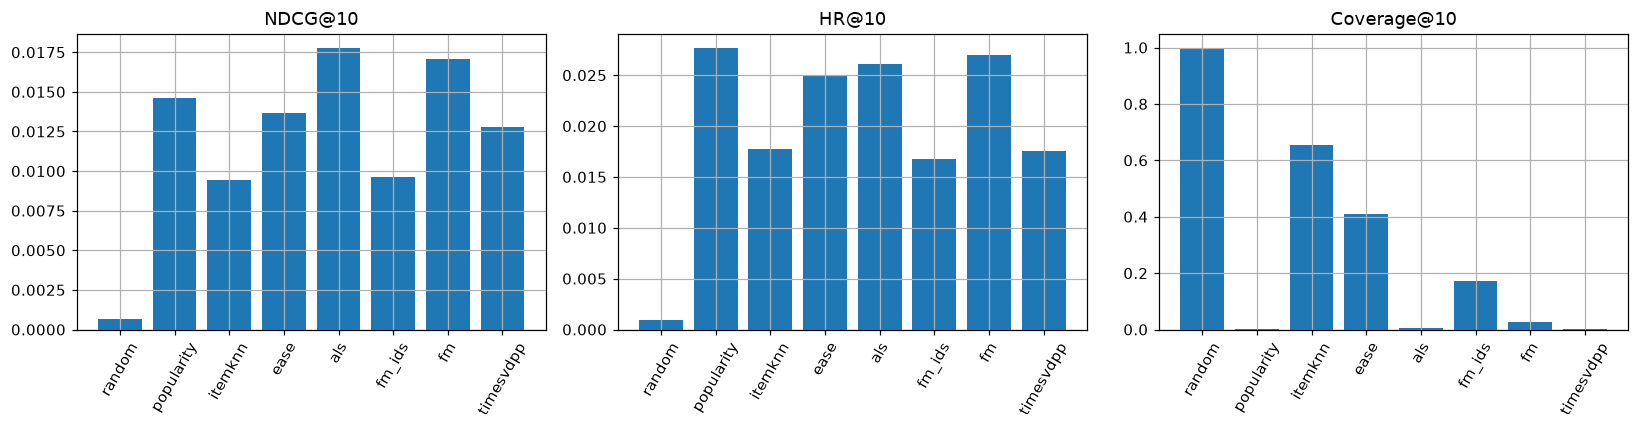

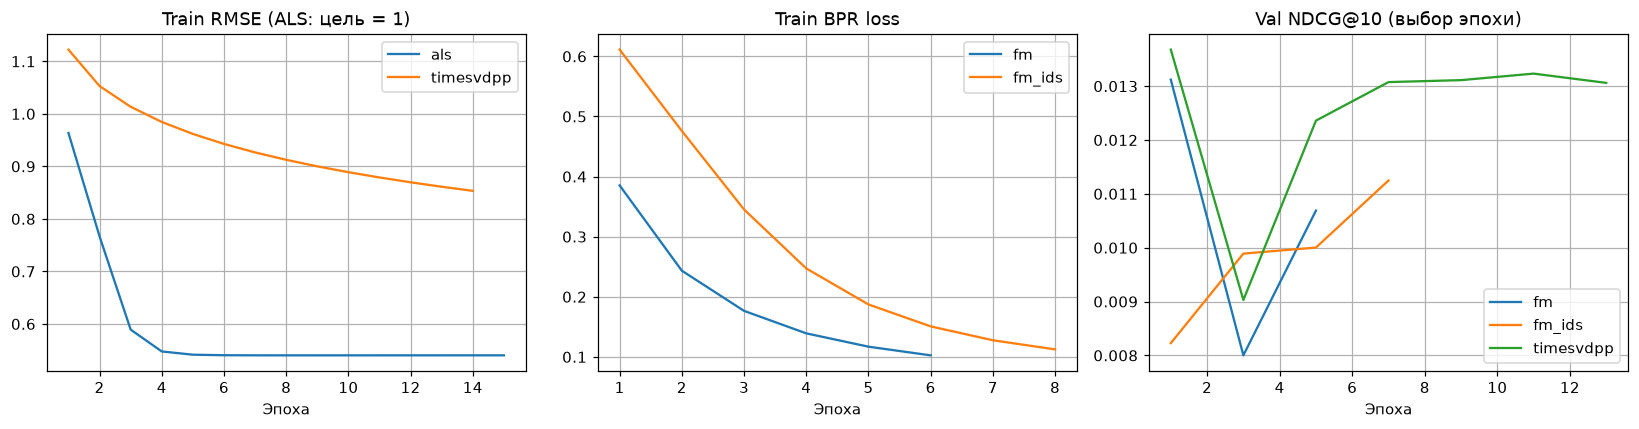

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['ndcg', 'hr', 'coverage']):
    ax.bar(names, [RUN[name]['test'][metric] for name in names])
    ax.set_title({'ndcg': 'NDCG@10', 'hr': 'HR@10', 'coverage': 'Coverage@10'}[metric])
    ax.tick_params(axis='x', rotation=60)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ['als', 'fm', 'fm_ids', 'timesvdpp']:
    history = RUN[name]['history'] or {}
    for key, ax in [('rmse', axes[0]), ('loss', axes[0] if name == 'als' else axes[1])]:
        values = history.get(key)
        if values:
            ax.plot(range(1, len(values) + 1), values, label=name)
    val = history.get('val_ndcg')
    if val:
        step = RUN[name]['params'].get('eval_every', 2)
        axes[2].plot(np.arange(len(val)) * step + 1, val, label=name)
for ax, title in zip(axes, ['Train RMSE (ALS: цель = 1)', 'Train BPR loss', 'Val NDCG@10 (выбор эпохи)']):
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
    if ax.lines:
        ax.legend()
fig.tight_layout()
plt.show()


In [14]:
titles = dict(zip(meta['item_idx'].to_list(), meta['title'].to_list()))
for uid in list(RUN['popularity']['examples']):
    print(f'Пользователь {uid}')
    history = inter.filter((pl.col('user_idx') == uid) & (pl.col('split') == 'train')).sort('ts')
    display(history.tail(8).join(meta.select('item_idx', 'title'), on='item_idx').select('title', 'rating'))
    rows = []
    for name in names:
        for rank, item in enumerate(RUN[name]['examples'][uid], 1):
            rows.append({'модель': name, 'место': rank, 'товар': titles.get(item, ''),
                         'попадание': item in test_set.rel[uid]})
    with pl.Config(tbl_rows=80, fmt_str_lengths=80):
        display(pl.DataFrame(rows))

Пользователь 1


title,rating
str,f32
"""PowerA Officially Licensed PSP…",5.0
"""PowerA Nintendo Official Exped…",5.0
"""Saitek Mad Catz STRIKE7 Modula…",1.0
"""PlayStation Vita Memory Card 6…",4.0
"""EPOS Sennheiser GSP 300 Gaming…",3.0
"""Hard Case for Meta Quest 2 JSV…",5.0
"""Cooler Master MH-751 MH751 2.0…",5.0
"""HyperX Cloud Alpha – Gaming He…",5.0


модель,место,товар,попадание
str,i64,str,bool
"""random""",1,"""Turtle Beach Titanfall Ear Force Atlas Official Xbox One Xbox 360 PC Gaming Head…",false
"""random""",2,"""Skylanders SWAP Force Nitro Magna Charge""",false
"""random""",3,"""BUBM Portable Carrying Case Compatible with PS5/PS4/ PS4 PRO/PS3/Xbox One/Xbox S…",false
"""random""",4,"""Doctor Lautrec and the Forgotten Knights - Nintendo 3DS""",false
"""random""",5,"""Red Star - PlayStation 2""",false
"""random""",6,"""Samsung Hmd Odyssey Windows Mixed Reality Headset with 2 Wireless Controllers (X…",false
"""random""",7,"""KontrolFreek FPS Freek Vortex for Xbox One and Xbox Series X Controller | Perfor…",false
"""random""",8,"""Resident Evil: Revelations 2 - Xbox 360""",false
"""random""",9,"""Heroes of Might and Magic V: Hammers of Fate | PC Code - Ubisoft Connect""",false


Пользователь 31


title,rating
str,f32
"""SOCOM II U.S. Navy Seals - Pla…",3.0
"""Frontlines: Fuel of War - PC""",1.0
"""Battlefield: Bad Company 2 - P…",2.0
"""Divinity II: The Dragon Knight…",5.0
"""Alice: Madness Returns - PC""",5.0


модель,место,товар,попадание
str,i64,str,bool
"""random""",1,"""Logitech G Rumblepad 2 Vibration Feedback Gamepad""",false
"""random""",2,"""100 Classic Books - Nintendo DS""",false
"""random""",3,"""Syberia Collector's Edition 1 & 2""",false
"""random""",4,"""KontrolFreek FPS Freek Galaxy Purple for Xbox One and Xbox Series X Controller |…",false
"""random""",5,"""Unreal Tournament 2004 (Editor's Choice Edition)""",false
"""random""",6,"""Turtle Beach - Ear Force Chat Cable for PlayStation 4 Headset Compatibility - PS…",false
"""random""",7,"""Kid Icarus: Uprising""",false
"""random""",8,"""Amplitude - PlayStation 2""",false
"""random""",9,"""Star Fox""",false


Пользователь 33


title,rating
str,f32
"""Plants vs. Zombies Garden Warf…",5.0
"""Dragon Quest Builders - Ninten…",5.0
"""HORI Nintendo Switch Mario Kar…",5.0
"""Hello Neighbor - Nintendo Swit…",4.0


модель,место,товар,попадание
str,i64,str,bool
"""random""",1,"""SeaWorld Adventure Parks Shamu's Deep Sea Adventure - PlayStation 2""",false
"""random""",2,"""Deadfall Adventures - PC""",false
"""random""",3,"""Component AV Cable for Nintendo Wii to HDTV""",false
"""random""",4,"""Logitech G403 Prodigy RGB Gaming Mouse – 16.8 Million Color Backlighting, 6 Prog…",false
"""random""",5,"""4M/13FT Braided Goldplated Play and Charge Cable for PS4, Xbox One Controllers a…",false
"""random""",6,"""Pythons Vertical Stand for PS4 Console-Black""",false
"""random""",7,"""Price Is Right Decades - Xbox 360""",false
"""random""",8,"""Control PS4 - PlayStation 4""",false
"""random""",9,"""Zumba Fitness Rush - Xbox 360""",false


## 7. Выводы

1. Наибольший test NDCG@10 у als: 0.0178, HR@10 — 0.0261.
   Выбранные параметры: `{'f': 64, 'iterations': 15, 'lam': 10.0, 'implicit': True, 'alpha': 0.0}`.
   FM с метапризнаками даёт NDCG@10 0.0171, EASE — 0.0137.
2. Лучший val NDCG@10 implicit ALS — 0.0208, explicit ALS — 0.0040.
   При α=2 val NDCG@10 равен 0.0008. Test-оценка рассчитана только
   для выбранной по val конфигурации ALS; отдельного test-сравнения двух постановок нет.
3. Test NDCG@10 FM с метапризнаками — 0.0171, с одними ID — 0.0096:
   разница +77.5%. Это сравнение выбранных конфигураций; помимо признаков
   могут различаться параметры обучения и seed.
   Пользовательские признаки рассчитаны по train.
4. Лучший val NDCG@10 FM с BPR — 0.0145, с MSE — 0.0011.
   Сравнение относится к проверенной сетке параметров. Кривые обучения приведены выше;
   значения разных функций потерь нельзя напрямую сравнивать между собой.
5. Test NDCG@10 timeSVD++ — 0.0128, выбранного ALS — 0.0178.
   Чтобы отдельно измерить вклад временных компонент, нужен эксперимент с их отключением.
6. Item-KNN даёт test NDCG@10 0.0094, EASE — 0.0137.
   Val NDCG@10 Item-KNN — 0.0159.
   Причину изменения качества между val и test по этим результатам установить нельзя.
7. Наибольший HR@10 у popularity: 0.0277.
   Popularity даёт NDCG@10 0.0146.
   Coverage@10: ALS — 0.005, FM с метапризнаками — 0.027,
   FM с ID — 0.172, timeSVD++ — 0.002.

Ограничения: оцениваются только пользователи с историей в train
и товары с не менее чем 10 train-взаимодействиями. Результаты не описывают
качество для новых пользователей и товаров. Разнообразие рекомендаций не оптимизировалось.
